In [1]:
import os
import json
import random
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pickle
import pandas as pd
import torch
import torch.nn.functional as F
import re
import time
from scipy.stats import gaussian_kde
from sklearn.neighbors import KDTree

import contextlib
import hashlib
import inspect
import platform
import sys



In [2]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'  # Catch errors immediately

import torch
torch.cuda.empty_cache()

In [3]:
from modules import (
    get_data_from_trajectory_id,
    Step_1,
    Step_2,
    CombinedHamiltonianLayer,
    SimpleStackedHamiltonianNetwork,
    ReverseStep2,
    ReverseStep1,
    ReverseCombinedHamiltonianLayer,
    InverseStackedHamiltonianNetwork,
    prediction_loss,
    prediction_loss_euclidean,
    load_checkpoint,
    count_parameters,
    hsic_loss_statistics_only,

    )

In [4]:
from modules import (    

    test_model_in_single_trajectory,
    Autoregressive_Handoff_Inference_Protocol,
    Batched_Autoregressive_Handoff_Inference_Protocol,
    time_inference_gpu,
    test_model_all_observations_all_trajectories,
    plot_summary_statistics,
    time_inference_gpu_single_trajectory,
    test_model_varying_observation_single_trajectory,
    plot_varying_observation_results,
    test_model_variance_with_varying_observed_points,
    plot_variance_results,
    visualize_epoch_metrics,
    compute_jacobian_functional,
    compute_symplectic_product,
    test_canonical_transformation_on_trajectory,
    attach_traj_id,
    infer_dt,
    local_lyapunov_times,
    summarize_task,
    row_to_latex,
    run_constancy_experiment_1d,
    )

In [5]:
save_dir_path = "./save_directory_noisy_full_pred_low_samples_4" 


In [6]:
with open("all_dataframes_low_samples.pkl", "rb") as f:
    loaded_dfs_low_samples = pickle.load(f)

# Access them like before:
train_df_low_samples = loaded_dfs_low_samples['train_df_low_samples']
val_df_low_samples = loaded_dfs_low_samples['val_df_low_samples']
test_df_low_samples = loaded_dfs_low_samples['test_df_low_samples']

train_id_df_low_samples = loaded_dfs_low_samples['train_id_df_low_samples']
val_id_df_low_samples = loaded_dfs_low_samples['val_id_df_low_samples']
test_id_df_low_samples = loaded_dfs_low_samples['test_id_df_low_samples']

with open("df_high_energy_low_samples.pkl", "rb") as f:
    df_high_energy_low_samples = pickle.load(f)


test_df_high_energy_low_samples = df_high_energy_low_samples['test_df_high_energy_low_samples']
test_id_df_high_energy_low_samples = df_high_energy_low_samples['test_id_df_high_energy_low_samples']

with open("all_dataframes_low_samples_multiple_periods.pkl", "rb") as f:
    df_low_samples_multiple_periods = pickle.load(f)

test_df_low_samples_multiple_periods = df_low_samples_multiple_periods['data_df_low_samples_multiple_periods']
test_id_df_low_samples_multiple_periods = df_low_samples_multiple_periods['id_df_low_samples_multiple_periods']


In [7]:

SIGMA2_OLD = 0.1
COORDS = ['x', 'u']   # q, p for this task

# within-trajectory variance: variance INSIDE each trajectory, then averaged over trajectories
per_traj = []
for tid in train_id_df_low_samples['trajectory_id'].astype(int):
    sub = get_data_from_trajectory_id(train_id_df_low_samples, train_df_low_samples, [tid])
    if sub is not None and len(sub) > 1:
        per_traj.append(sub[COORDS].var(ddof=0))
within = pd.concat(per_traj, axis=1).T.mean()
pooled = train_df_low_samples[COORDS].var(ddof=0)

print("=== Task 1 (mass-spring) ===")
for c in COORDS:
    print(f"  {c}: within_var={within[c]:.4e}  pooled_var={pooled[c]:.4e}  "
          f"SNR_within@0.1={within[c]/SIGMA2_OLD:6.2f}  SNR_pooled@0.1={pooled[c]/SIGMA2_OLD:6.2f}")
print("\nPaste this line into the HH notebook:")
print("  ('Task1', {" + ", ".join(f"'{c}': {within[c]:.6e}" for c in COORDS) + "}),")

=== Task 1 (mass-spring) ===
  x: within_var=5.7059e-01  pooled_var=5.7184e-01  SNR_within@0.1=  5.71  SNR_pooled@0.1=  5.72
  u: within_var=6.0054e-01  pooled_var=6.0326e-01  SNR_within@0.1=  6.01  SNR_pooled@0.1=  6.03

Paste this line into the HH notebook:
  ('Task1', {'x': 5.705888e-01, 'u': 6.005445e-01}),


In [ ]:


DATA_DF   = train_df_low_samples
ID_DF     = train_id_df_low_samples
TASK_NAME = "T1 (mass--spring)"
Q_COLS    = ["x"];  P_COLS = ["u"]
N_MIN     = 5;      R_MIN  = 8
SEED      = 0;      

# ----- prepare -----
df = attach_traj_id(DATA_DF, ID_DF)
dt = infer_dt(df)
print(f"[data] {TASK_NAME}: {len(df)} samples, "
      f"{df['traj_id'].nunique()} trajectories, dt={dt:.4g}")

# ----- estimate (seed printed in the [setup] block) -----
tau_L, details = local_lyapunov_times(
    df, dt=dt,
    min_neighbors=N_MIN,          # REQUIRED
    min_region_points=R_MIN,      # REQUIRED
    q_cols=Q_COLS, p_cols=P_COLS, t_col="t",
    traj_col="traj_id",
    w=None,                 # self-defined if None
    K_max=None,             # self-defined if None
    n_eps=8, eps_lo_pct=1.0, eps_hi_pct=20.0,
    lpower=1.0, epower=1.0,
    fwhm_frac_max=0.25,
    zero_tol_factor=2.0,
    min_valid_eps=5,
    curve_len_factor=4,
    rng=0, 
    return_details=True,
    verbose=True)

# ----- summarize into the standardized record -----train_df_low_samples
rec = summarize_task(TASK_NAME, df, tau_L, details, n_min=N_MIN, r_min=R_MIN)

# ----- report: the table row and the final T_max -----
print(f"\n[seed] rng={SEED}")
print(f"[T_record] {rec['T_record']:.3f}   [T_max] {rec['T_max']:.3f}")
print("\nLaTeX row:")
print(row_to_latex(rec))



[data] T1 (mass--spring): 768 samples, 24 trajectories, dt=0.2094
[setup] N=768 samples, 24 trajectories, dim(q,p)=2
[setup] Theiler w=14 steps, K_max=31 steps
[setup] eps-subsample seed (rng)=0
[setup] eps grid: [0.1401 0.1771 0.2237 0.2827 0.3572 0.4514 0.5703 0.7206]
[done] finite tau_L: 3, inf (regular): 525, NaN: 240

[seed] rng=0
[T_record] 6.493   [T_max] 6.493

LaTeX row:
T1 (mass--spring) & 5 & 8 & 768 & 525 & 3 & 240 & $59.92$ & $62.03$ & $37.75$ & $6.493$ & $6.493$ \\


In [ ]:
Tmax = np.float32(rec["T_max"])
Tmax

np.float32(6.4926248)

In [7]:
Tmax = np.float32(6.4926248)

In [12]:
k=1
mass=1
constant = -(k / mass)
omega = np.sqrt(-constant)
period = 2*np.pi/omega
print(f"Period is constant and = {period:.3f}")



    

Period is constant and = 6.283


In [8]:
device = "cuda"
mapping_net = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)

In [9]:


checkpoint_path = os.path.join(save_dir_path, "best_model.pt")

load_checkpoint(path=checkpoint_path, mapping_net=mapping_net, device=device, optimizer=None, scheduler=None)

inverse_net = InverseStackedHamiltonianNetwork(forward_network=mapping_net)


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [12]:
canonicity_results = test_canonical_transformation_on_trajectory(get_data_from_trajectory_id,
    compute_jacobian_functional,
    compute_symplectic_product,                                            
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    3,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    tolerance=1e-5,
    verbose=True,)

=== Canonical Transformation Test — Trajectory 3 ===
(4 segment(s), 97 total points, tolerance=1.0e-05)

MappingNet: d(Q,P)/d(q,p)
  ✓ All 97 points pass (max residual: 4.77e-07)
  Residual max|M^T Ω M - Ω| per point:
    Mean:   1.62e-07 (std=1.09e-07)
    Median: 1.19e-07 [IQR: 1.19e-07, 2.38e-07]
    Min:    0.00e+00
    Max:    4.77e-07

InverseNet: d(q,p)/d(Q,P)
  ✓ All 97 points pass (max residual: 9.54e-07)
  Residual max|M^T Ω M - Ω| per point:
    Mean:   1.71e-07 (std=1.54e-07)
    Median: 1.19e-07 [IQR: 5.96e-08, 2.98e-07]
    Min:    0.00e+00
    Max:    9.54e-07

=== Table row (Task = trajectory 3) ===
  M  max    = 4.77e-07
  M  median = 1.19e-07
  M^-1 max    = 9.54e-07
  M^-1 median = 1.19e-07
  LaTeX: 4.77e-07 & 1.19e-07 & 9.54e-07 & 1.19e-07 \\


In [15]:
print(f"Number of parameters are: {count_parameters(mapping_net)}, with number of training samples: {train_df_low_samples.shape[0]}\nThat is a ratio of parameters/samples of: {count_parameters(mapping_net)/train_df_low_samples.shape[0]}")

Number of parameters are: 82560, with number of training samples: 768
That is a ratio of parameters/samples of: 107.5


In [ ]:

with open("benchmark_outputs/hjn_task1_multiple_periods_final.pkl", "rb") as f:
    time_results_multiple_periods = pickle.load(f)

In [14]:
all_trajectories_results_multiple_periods = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    verbose=True,
)

Observation index 0/96, mean loss across trajectories: 0.061104
Observation index 1/96, mean loss across trajectories: 0.063729
Observation index 2/96, mean loss across trajectories: 0.070426
Observation index 3/96, mean loss across trajectories: 0.078003
Observation index 4/96, mean loss across trajectories: 0.083955
Observation index 5/96, mean loss across trajectories: 0.087154
Observation index 6/96, mean loss across trajectories: 0.089075
Observation index 7/96, mean loss across trajectories: 0.090631
Observation index 8/96, mean loss across trajectories: 0.088882
Observation index 9/96, mean loss across trajectories: 0.087516
Observation index 10/96, mean loss across trajectories: 0.078093
Observation index 11/96, mean loss across trajectories: 0.066968
Observation index 12/96, mean loss across trajectories: 0.058169
Observation index 13/96, mean loss across trajectories: 0.054350
Observation index 14/96, mean loss across trajectories: 0.054596
Observation index 15/96, mean loss 

In [15]:
#SAVE

with open("./prediction_results_all_trajectories/task_1_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods, f)

In [13]:
#LOAD
with open("./prediction_results_all_trajectories/task_1_results_multiple_periods.pkl", "rb") as f:
    all_trajectories_results_multiple_periods = pickle.load(f)


=== Raw Statistics (loss) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.062931
Std of medians: 0.018264
Median of medians: 0.061770
IQR of medians: [0.047252, 0.074989]
95% BCa CI for mean of medians (over trajectories): [0.056010, 0.070299]
N_traj=24, N_obs=97

=== Normalized Statistics (energy-normalized loss L/√E) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.083255
Std of medians: 0.007852
Median of medians: 0.082466
IQR of medians: [0.077139, 0.087762]
95% BCa CI for mean of medians (over trajectories): [0.080398, 0.086525]
N_traj=24, N_obs=97


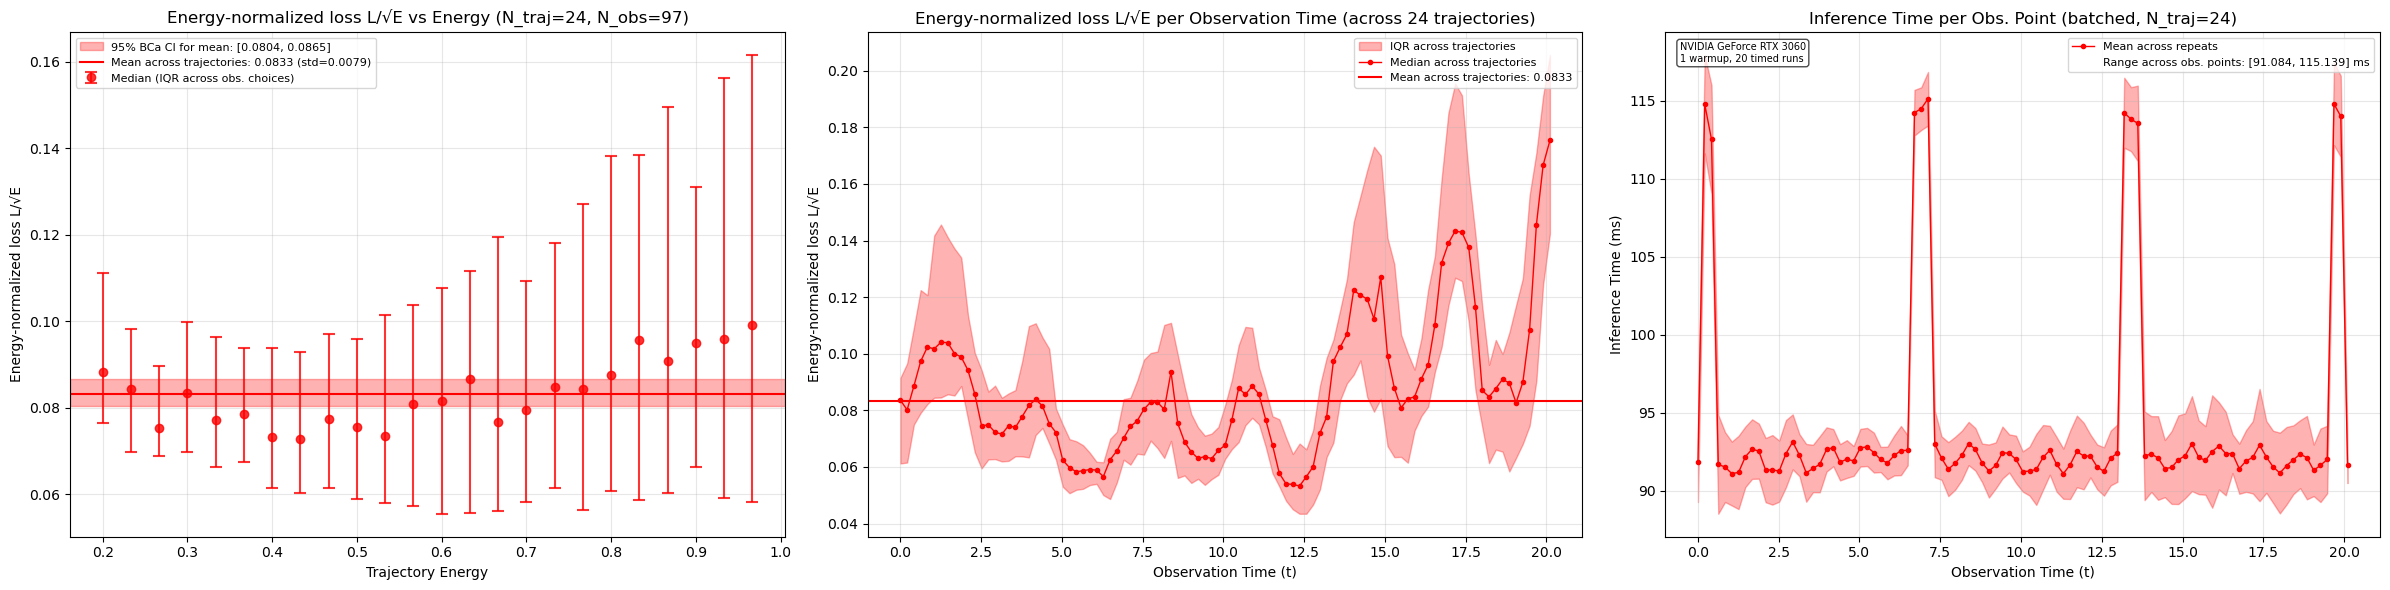

In [16]:
plot_summary_statistics(all_trajectories_results_multiple_periods, normalized=True, figsize=(16, 6), timing_stats_batch=time_results_multiple_periods['timing_stats'], timing_stats_single=None, band_alpha=0.3)

In [14]:
variance_results_multiple_periods = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.013468
IQR: [0.010110, 0.015440]
95% BCa bootstrap CI for median (over trajectories): [0.011681, 0.014849]
N_traj=24, N_obs=97, N_permutations=20
First valid point count: 3


In [15]:
#SAVE

with open("./variance_results/task_1_variance_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(variance_results_multiple_periods, f)

In [5]:
#LOAD
with open("./variance_results/task_1_variance_results_multiple_periods.pkl", "rb") as f:
    variance_results_multiple_periods = pickle.load(f)

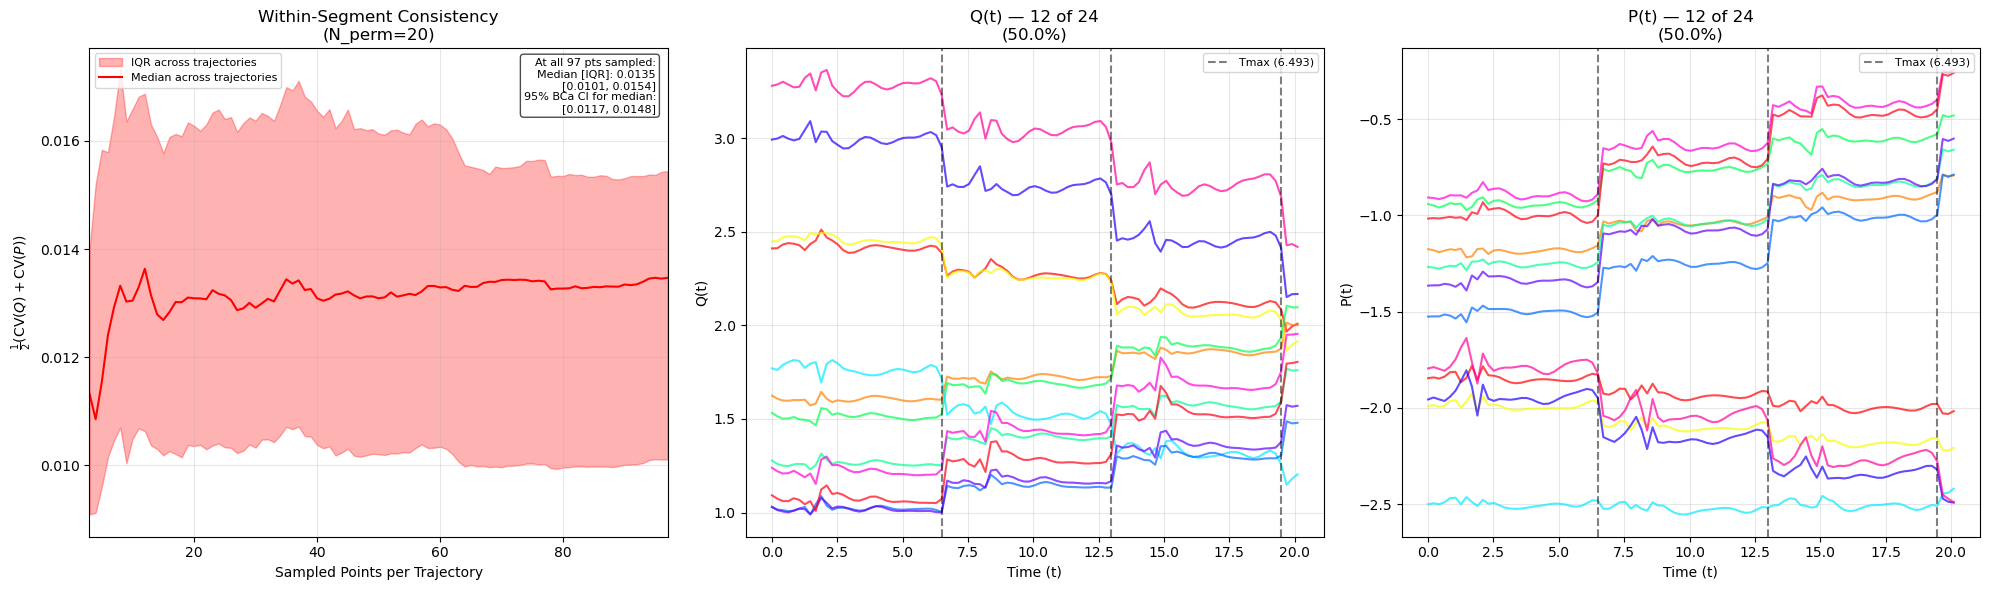

In [6]:
plot_variance_results(variance_results_multiple_periods, only_plot_percentage=0.5)

In [18]:
print(all_trajectories_results_multiple_periods['median_representative_id'])

3


In [19]:
single_trajectory_multiple_periods_results = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    all_trajectories_results_multiple_periods['median_representative_id'],
    mapping_net,
    inverse_net,
    device,
    Tmax,
    case="harmonic_oscillator",
    length=3.0, k=1, mass=1, g=9.81, constant=2.4,
    verbose=True,
)

Observation index 0/96, loss: 0.004008
Observation index 1/96, loss: 0.003249
Observation index 2/96, loss: 0.002659
Observation index 3/96, loss: 0.002484
Observation index 4/96, loss: 0.002781
Observation index 5/96, loss: 0.003384
Observation index 6/96, loss: 0.003762
Observation index 7/96, loss: 0.004010
Observation index 8/96, loss: 0.004249
Observation index 9/96, loss: 0.006013
Observation index 10/96, loss: 0.004068
Observation index 11/96, loss: 0.003983
Observation index 12/96, loss: 0.004105
Observation index 13/96, loss: 0.004156
Observation index 14/96, loss: 0.003644
Observation index 15/96, loss: 0.002539
Observation index 16/96, loss: 0.001575
Observation index 17/96, loss: 0.001265
Observation index 18/96, loss: 0.001435
Observation index 19/96, loss: 0.001655
Observation index 20/96, loss: 0.001812
Observation index 21/96, loss: 0.001985
Observation index 22/96, loss: 0.002112
Observation index 23/96, loss: 0.002128
Observation index 24/96, loss: 0.002112
Observatio

In [20]:
#SAVE

with open("./prediction_results_single_trajectory/task_1_single_traj_results_multiple_periods.pkl", "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results, f)

In [ ]:
#LOAD
with open("./prediction_results_single_trajectory/task_1_single_traj_results_multiple_periods.pkl", "rb") as f:
    single_trajectory_multiple_periods_results = pickle.load(f)

In [21]:
obs_idx = 0

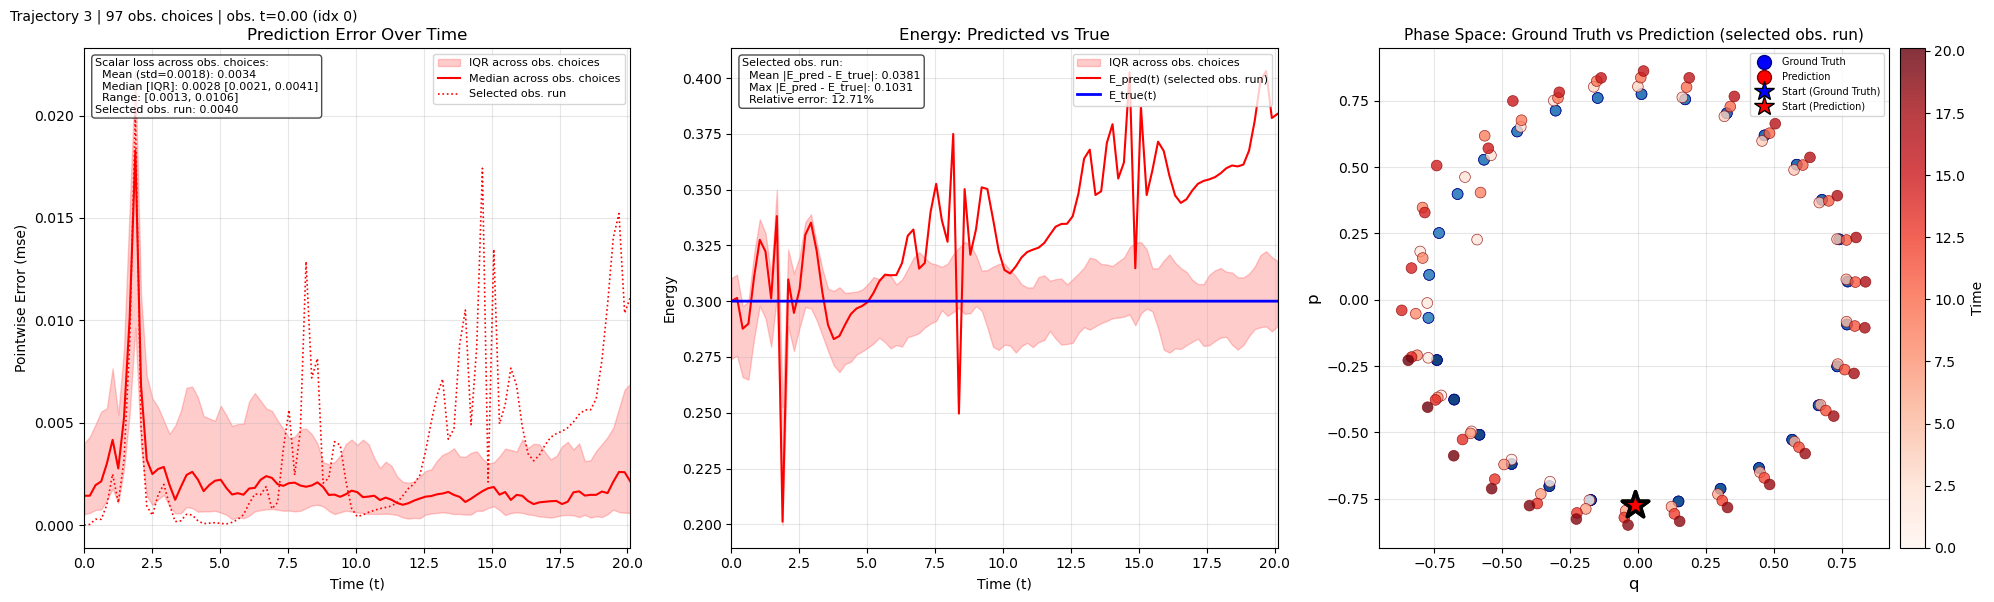

In [22]:
plot_varying_observation_results(single_trajectory_multiple_periods_results, obs_idx=obs_idx, figsize=(20,6), connect_points=False, iqr_alpha = 0.2)

In [23]:
print(f"The max energy of a trajectory in the training set is: {train_id_df_low_samples['energy'].max():.3f}\nThe high energy testing set has energies in the range: {test_id_df_high_energy_low_samples['energy'].min():.3f}-{test_id_df_high_energy_low_samples['energy'].max():.3f}")

The max energy of a trajectory in the training set is: 0.968
The high energy testing set has energies in the range: 1.118-1.942


In [24]:

with open("benchmark_outputs/hjn_task1_high_energy.pkl", "rb") as f:
    time_results_high_energy = pickle.load(f)

In [25]:
all_trajectories_results_high_energy = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    verbose=True,
)

Observation index 0/31, mean loss across trajectories: 0.072763
Observation index 1/31, mean loss across trajectories: 0.073326
Observation index 2/31, mean loss across trajectories: 0.077310
Observation index 3/31, mean loss across trajectories: 0.084435
Observation index 4/31, mean loss across trajectories: 0.083542
Observation index 5/31, mean loss across trajectories: 0.087025
Observation index 6/31, mean loss across trajectories: 0.101754
Observation index 7/31, mean loss across trajectories: 0.155656
Observation index 8/31, mean loss across trajectories: 0.178610
Observation index 9/31, mean loss across trajectories: 0.355501
Observation index 10/31, mean loss across trajectories: 0.225317
Observation index 11/31, mean loss across trajectories: 0.110946
Observation index 12/31, mean loss across trajectories: 0.085855
Observation index 13/31, mean loss across trajectories: 0.087381
Observation index 14/31, mean loss across trajectories: 0.090278
Observation index 15/31, mean loss 

In [26]:
#SAVE

with open("./prediction_results_all_trajectories/task_1_results_high_energy.pkl", "wb") as f:
    pickle.dump(all_trajectories_results_high_energy, f)

In [ ]:
#LOAD
with open("./prediction_results_all_trajectories/task_1_results_high_energy.pkl", "rb") as f:
    all_trajectories_results_high_energy = pickle.load(f)


=== Raw Statistics (loss) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.080188
Std of medians: 0.033061
Median of medians: 0.074898
IQR of medians: [0.053393, 0.092684]
95% BCa CI for mean of medians (over trajectories): [0.068731, 0.093764]
N_traj=25, N_obs=32

=== Normalized Statistics (energy-normalized loss L/√E) ===
Per-trajectory summary: median across obs. choices
Mean of medians: 0.064391
Std of medians: 0.023301
Median of medians: 0.060584
IQR of medians: [0.044395, 0.073502]
95% BCa CI for mean of medians (over trajectories): [0.056260, 0.074174]
N_traj=25, N_obs=32


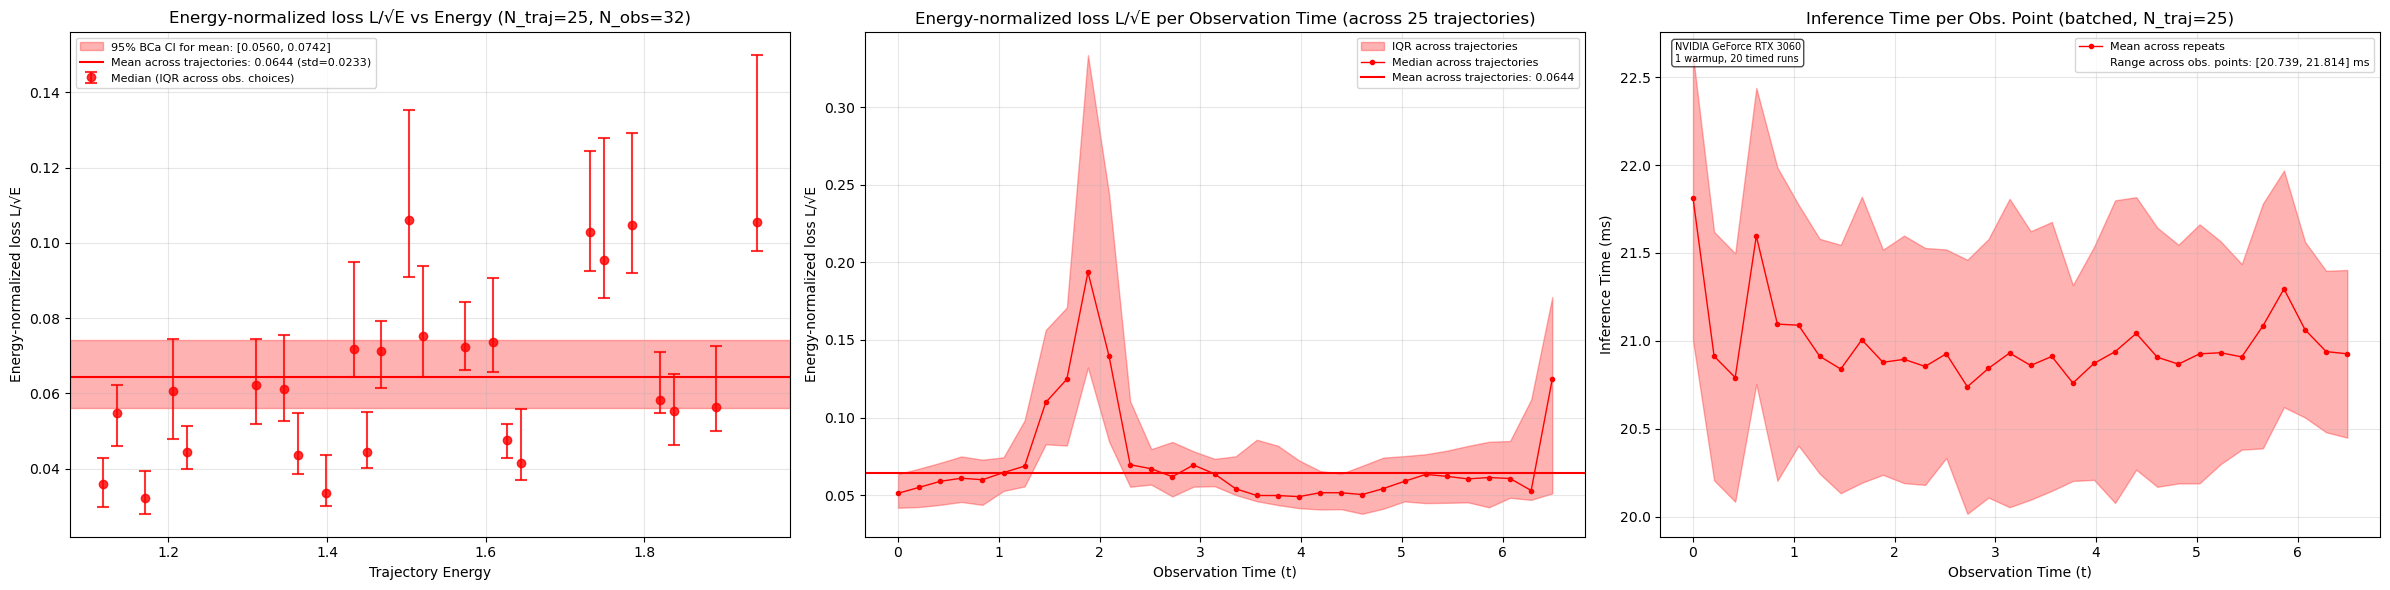

In [27]:
plot_summary_statistics(all_trajectories_results_high_energy, normalized=True, figsize=(16, 6), timing_stats_batch=time_results_high_energy['timing_stats'], timing_stats_single=None, band_alpha=0.3)

In [11]:
variance_results_high_energy = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)


#SAVE

with open("./variance_results/task_1_variance_results_high_energy.pkl", "wb") as f:
    pickle.dump(variance_results_high_energy, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.056543
IQR: [0.031283, 0.073067]
95% BCa bootstrap CI for median (over trajectories): [0.033731, 0.069424]
N_traj=25, N_obs=32, N_permutations=20
First valid point count: 2


/tmp/ipykernel_8213/2054056240.py:332: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab10' if N_traj <= 10 else 'tab20' if N_traj <= 20 else 'hsv')(


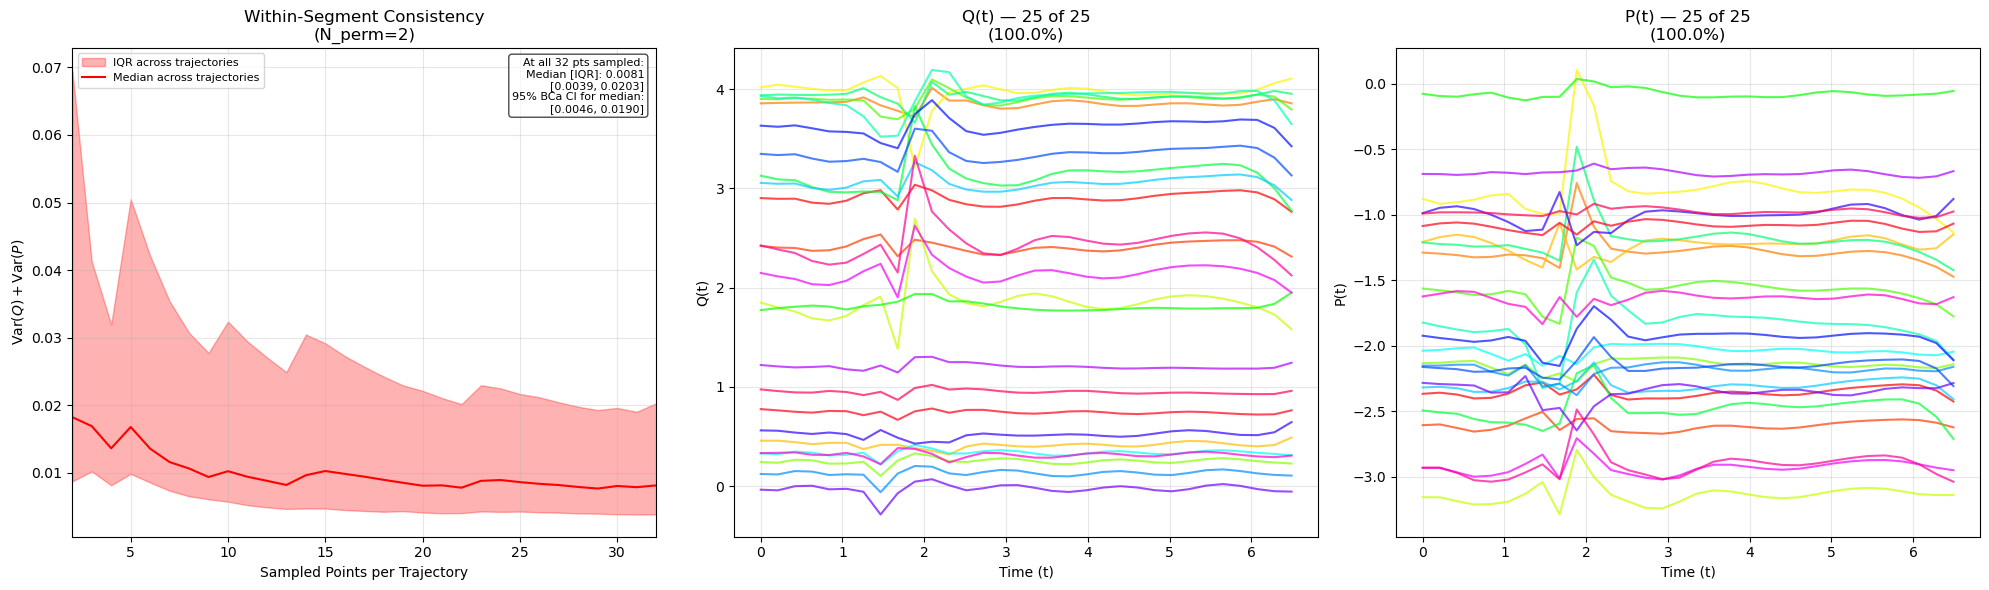

In [49]:
plot_variance_results(variance_results_high_energy, only_plot_percentage=1.0)

In [10]:


SETS = {"Train": (train_df_low_samples, train_id_df_low_samples),
"TestA": (test_df_low_samples_multiple_periods, test_id_df_low_samples_multiple_periods),
"TestB": (test_df_high_energy_low_samples, test_id_df_high_energy_low_samples)}



res_ms = run_constancy_experiment_1d(
    mapping_net, inverse_net, Tmax=Tmax, sets=SETS, sigma2=0.1,
)


#SAVE

with open("./constancy_results/task_1_constancy_results.pkl", "wb") as f:
    pickle.dump(res_ms, f)







model ea153cbc02beadd2 | outputs 494c8dad5809764c
Train  n_traj=24  n_seg=24  D0 0.0235 [0.0219, 0.0307] | W0max 0.0393 [0.0337, 0.0543] | rms_delta 0.0373 [0.0321, 0.0442] | max_delta 0.0855 [0.0747, 0.107] | rms_disp 1.51 [1.22, 1.72] | noise ratio 0.0833 | D0/Train 1 | floor max 8.50e-07
TestA  n_traj=24  n_seg=96  D0 0.0232 [0.0214, 0.0275] | W0max 0.0509 [0.0366, 0.0593] | rms_delta 0.0354 [0.0294, 0.0428] | max_delta 0.105 [0.0806, 0.143] | rms_disp 1.5 [1.23, 1.73] | noise ratio 0.0791 | D0/Train 0.986 | floor max 1.47e-06
TestB  n_traj=25  n_seg=25  D0 0.0358 [0.0269, 0.0573] | W0max 0.0761 [0.0574, 0.151] | rms_delta 0.095 [0.0648, 0.145] | max_delta 0.261 [0.185, 0.582] | rms_disp 2.41 [2.28, 2.59] | noise ratio 0.212 | D0/Train 1.52 | floor max 1.64e-06


In [28]:
print(all_trajectories_results_high_energy['median_representative_id'])

6


In [29]:
single_trajectory_high_energy_results = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    all_trajectories_results_high_energy['median_representative_id'],
    mapping_net,
    inverse_net,
    device,
    Tmax,
    case="harmonic_oscillator",
    length=3.0, k=1, mass=1, g=9.81, constant=2.4,
    verbose=False,
)

In [30]:
#SAVE

with open("./prediction_results_single_trajectory/task_1_single_traj_results_high_energy.pkl", "wb") as f:
    pickle.dump(single_trajectory_high_energy_results, f)

In [ ]:
#LOAD
with open("./prediction_results_single_trajectory/task_1_single_traj_results_high_energy.pkl", "rb") as f:
    single_trajectory_high_energy_results = pickle.load(f)

In [31]:
obs_idx = 0

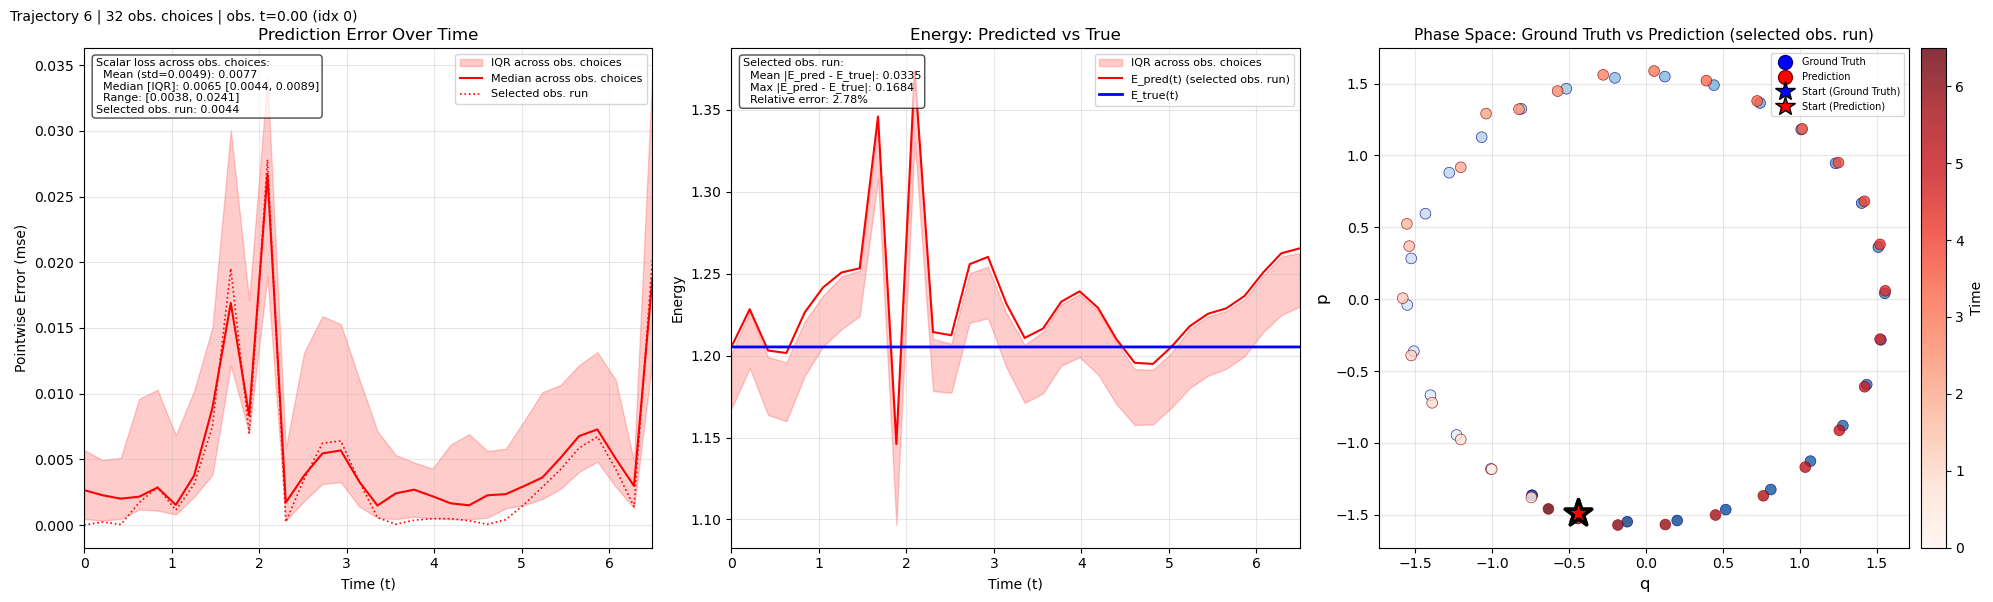

In [34]:
plot_varying_observation_results(single_trajectory_high_energy_results, obs_idx=obs_idx, figsize=(20,6), connect_points=False, iqr_alpha = 0.2)

In [21]:
"""
Latent <-> physics recovery for HJN.

Complements the constancy experiment. Constancy shows (Q,P) are constant ALONG
an orbit (the latents are SOME invariant). This shows the CROSS-orbit fact: how
(Q,P) depend on the true conserved quantities (E, phi), and that a LOW-ORDER
polynomial reads them back out -- in-distribution.
No loss term ever sees E or phi (only reconstruction MAE + an HSIC penalty that
enforces independence BETWEEN Q and P, not identity WITH the physics), so the
recovery is emergent.

Two structural laws (the recovered DEGREE is a diagnostic of how affine the
learned canonical map is; nothing forces a particular degree a priori):
  * ENERGY: E = 1/2(q^2+p^2) is quadratic in (q,p); reported as the recovered
    degree-2 quadratic form (eigenvalues of its quadratic part give the
    positive-definite / closed-orbit check) AND the degree-3 form for fidelity.
  * PHASE: phi = atan2(q,p) is an ANGLE; reported as the degree-1 affine-angle
    one-liner AND the degree-2 form.

Statistics: errors live on a DETERMINISTIC grid with spatially correlated
residuals, so we do NOT bootstrap (no i.i.d. resampling unit). We report the
descriptive error field: median [p25, p75], p95. A true CI would need multiple
training seeds (hook at the bottom).

Reporting is feature-agnostic, so the same tables run on HJN's (Q,P) and the
baseline's C_k via `report_recovery(...)`.

Assumes `mapping_net` (encoder: mapping_net(q,p,t)->(Q,P,t)) and `device` exist.
torch is imported lazily inside the encoder so the analysis path runs without it.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold


# ======================================================================
# Data + encoding
# ======================================================================
def sho_initial_conditions(E, phi):
    """(E, phi) -> (q, p) for H = 1/2 (q^2+p^2). atan2(q,p)=phi, 1/2(q^2+p^2)=E."""
    E = np.asarray(E, float); phi = np.asarray(phi, float)
    return np.sqrt(2 * E) * np.sin(phi), np.sqrt(2 * E) * np.cos(phi)


def build_grid(E_lo, E_hi, n_E=40, n_phi=40):
    Ea = np.linspace(E_lo, E_hi, n_E)
    pa = np.linspace(-np.pi, np.pi, n_phi, endpoint=False)
    EE, PP = np.meshgrid(Ea, pa, indexing="ij")
    E, phi = EE.ravel(), PP.ravel()
    q, p = sho_initial_conditions(E, phi)
    return E, phi, q, p


def encode_at_reference_time(mapping_net, q, p, device, reference_time=0.0):
    """No torch.no_grad(): the HJL forward uses autograd internally; .detach() outputs."""
    import torch
    q_t = torch.as_tensor(np.asarray(q, np.float32), device=device)
    p_t = torch.as_tensor(np.asarray(p, np.float32), device=device)
    t_t = torch.full_like(q_t, float(reference_time))
    Q, P, _ = mapping_net(q_t, p_t, t_t)
    return Q.detach().cpu().numpy().astype(float), P.detach().cpu().numpy().astype(float)


def encode_grid(mapping_net, device, E_lo, E_hi, n_E=40, n_phi=40, reference_time=0.0):
    E, phi, q, p = build_grid(E_lo, E_hi, n_E, n_phi)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    return dict(E=E, phi=phi, q=q, p=p, feats=np.column_stack([Q, P]), band=(E_lo, E_hi))





# ======================================================================
# Core: out-of-fold prediction, generalization, equations
# ======================================================================
def _r2(y, yhat):
    y = np.asarray(y, float)
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


def _poly(degree, scale=False):
    """Polynomial least-squares read-out. `scale` toggles input standardisation:
    it leaves predictions and R^2 unchanged (an invertible affine reparameterisation
    of the features) and only changes coefficient values, so it is OFF by default
    so that the fitted model IS the equation reported in raw (Q,P) units. Turn it
    ON only if a high-degree solve is ill-conditioned; it never affects results."""
    steps = [StandardScaler()] if scale else []
    steps += [PolynomialFeatures(degree, include_bias=True),
              LinearRegression(fit_intercept=False)]
    return make_pipeline(*steps)


def _oof_scalar(feats, y, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, float); pred = np.zeros_like(y)
    for tr, te in kf.split(feats):
        pred[te] = _poly(degree, scale).fit(feats[tr], y[tr]).predict(feats[te])
    return pred




def _oof_phase(feats, phi, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    c, s = np.cos(phi), np.sin(phi); ch, sh = np.zeros_like(c), np.zeros_like(s)
    for tr, te in kf.split(feats):
        m = _poly(degree, scale).fit(feats[tr], np.column_stack([c[tr], s[tr]]))
        o = m.predict(feats[te]); ch[te], sh[te] = o[:, 0], o[:, 1]
    return np.arctan2(sh, ch)




def angular_error_deg(phi_true, phi_hat):
    d = np.arctan2(np.sin(phi_hat - phi_true), np.cos(phi_hat - phi_true))
    return np.abs(d) * 180.0 / np.pi


def err_stats(abs_err):
    """Descriptive spread (no distributional assumption, no bootstrap)."""
    a = np.asarray(abs_err, float)
    q25, med, q75, p95 = np.percentile(a, [25, 50, 75, 95])
    return dict(median=med, p25=q25, p75=q75, p95=p95, mean=a.mean())


def _terms(names, coef):
    """Format a polynomial as a coefficient string in raw (Q,P) units."""
    parts = [f"{c:+.4f}" if n == "1" else f"{c:+.4f}·{n}" for n, c in zip(names, coef)]
    return " ".join(parts).replace("Q P", "QP")


def energy_equation(feats, E, degree, scale=False):
    """Fit the energy read-out and expose both its coefficients (raw Q,P units,
    the displayed equation) and the fitted model itself, so the SAME object can be
    reused as the time-shift instrument. For degree 2 we also return the quadratic
    part's eigenvalues (positive-definite => closed-orbit invariant)."""
    model = _poly(degree, scale).fit(feats, E)
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    coef = model.named_steps["linearregression"].coef_
    out = dict(names=names, coef=coef, degree=degree, model=model)
    if degree == 2 and feats.shape[1] == 2 and not scale:
        d = dict(zip(names, coef))
        M = np.array([[d["Q^2"], d["Q P"] / 2], [d["Q P"] / 2, d["P^2"]]])
        eig = np.linalg.eigvalsh(M)
        out.update(eig=eig, posdef=bool(eig.min() > 0))
    return out


def phase_poly_angle(feats, phi, degree, scale=False):
    """Fit the phase read-out and expose both the displayed equation
    (phi_hat = atan2(sin-poly, cos-poly), raw Q,P units; degree 1 = the affine-angle
    one-liner) and the fitted multi-output model, so the SAME object is reused as
    the time-shift instrument."""
    model = _poly(degree, scale).fit(feats, np.column_stack([np.cos(phi), np.sin(phi)]))
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    cos_coef, sin_coef = model.named_steps["linearregression"].coef_  # rows: cos, sin
    o = model.predict(feats)
    phi_hat = np.arctan2(o[:, 1], o[:, 0])
    return dict(num=_terms(names, sin_coef), den=_terms(names, cos_coef),
                err=angular_error_deg(phi, phi_hat), model=model)


# ======================================================================
# Reporters
# ======================================================================
def _fmt(s):
    return f"{s['median']:.4f} [{s['p25']:.4f}, {s['p75']:.4f}] p95={s['p95']:.4f}"


def report_recovery(res_train, name="HJN", degrees=(1, 2, 3, 4), scale=False):
    """Feature-agnostic (HJN (Q,P) or baseline C_k). R^2 ladders + descriptive
    error fields, in-distribution (train CV only). `scale` standardises features
    before the polynomial fit; it is OFF by default and never changes any reported
    number (see _poly)."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "=" * 78
    print(f"\n{bar}\n[{name}]  ENERGY RECOVERY     "
          f"train E in {res_train['band']}\n{bar}")
    print(f"{'deg':>3} | {'train R2':>9} || train |dE| med[IQR] p95 (rel%)")
    for dg in degrees:
        oof = _oof_scalar(ft, Et, dg, scale=scale)
        rt = np.median(np.abs(Et - oof) / np.abs(Et)) * 100
        print(f"{dg:>3} | {_r2(Et, oof):>9.4f} || "
              f"{_fmt(err_stats(np.abs(Et - oof)))} ({rt:.1f}%)")

    print(f"\n{bar}\n[{name}]  PHASE RECOVERY  (angular error in degrees)\n{bar}")
    print(f"{'deg':>3} | {'cos R2':>7} | {'sin R2':>7} || train ang.err med[IQR] p95")
    for dg in degrees:
        ph_tr = _oof_phase(ft, pt, dg, scale=scale)
        print(f"{dg:>3} | {_r2(np.cos(pt), np.cos(ph_tr)):>7.4f} | "
              f"{_r2(np.sin(pt), np.sin(ph_tr)):>7.4f} || "
              f"{_fmt(err_stats(angular_error_deg(pt, ph_tr)))}")


def report_equations(res_train, name="HJN"):
    """HJN structural laws (assumes 2 canonical latents)."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "-" * 78
    print(f"\n{bar}\n[{name}]  RECOVERED LAWS  (raw Q,P units; coefficients are "
          f"gauge-dependent -- the STRUCTURE is the robust claim)\n{bar}")

    eq2 = energy_equation(ft, Et, 2)
    print("ENERGY (degree-2):")
    print("  E = " + _terms(eq2["names"], np.round(eq2["coef"], 4)))
    print(f"  eigenvalues of quadratic part = {eq2['eig'].round(3)}  "
          f"positive-definite = {'YES' if eq2['posdef'] else 'NO'}  (=> closed-orbit invariant)")
    eq3 = energy_equation(ft, Et, 3)
    print("ENERGY (degree-3):")
    print("  E = " + _terms(eq3["names"], np.round(eq3["coef"], 4)))

    p1 = phase_poly_angle(ft, pt, 1); s1 = err_stats(p1["err"])
    print("PHASE (degree-1 affine-angle):")
    print(f"  phi_hat = atan2( {p1['num']} ,  {p1['den']} )")
    print(f"  angular error: median {s1['median']:.3f} deg "
          f"[{s1['p25']:.3f}, {s1['p75']:.3f}]  p95={s1['p95']:.3f} deg")
    p2 = phase_poly_angle(ft, pt, 2); s2 = err_stats(p2["err"])
    print("PHASE (degree-2):")
    print("  phi_hat = atan2( NUM , DEN ) with")
    print(f"    NUM = {p2['num']}")
    print(f"    DEN = {p2['den']}")
    print(f"  angular error: median {s2['median']:.3f} deg "
          f"[{s2['p25']:.3f}, {s2['p75']:.3f}]  p95={s2['p95']:.3f} deg")


# ======================================================================
# Read-out registry: fit once on the t=0 grid, reuse by degree
# ======================================================================
def fit_readouts(res_train, degrees=(1, 2, 3, 4), scale=False):
    """Fit, once, the energy and phase read-outs for every requested degree on the
    t=0 training grid, caching the actual fitted models. These are the SAME models
    whose coefficients report_equations displays, so the time-shift test applies
    the displayed equations rather than a separate fit. Returns
    {'energy': {d: model}, 'phase': {d: model}, 'degrees': (...)}. Phase models are
    multi-output, predicting [cos phi, sin phi]."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    energy = {d: energy_equation(ft, Et, d, scale)["model"] for d in degrees}
    phase  = {d: phase_poly_angle(ft, pt, d, scale)["model"] for d in degrees}
    return dict(energy=energy, phase=phase, degrees=tuple(degrees))


def predict_energy(readouts, feats, degree):
    return readouts["energy"][degree].predict(feats)


def predict_phase(readouts, feats, degree):
    """Recover the angle from the cached degree-`degree` (cos,sin) read-out."""
    o = readouts["phase"][degree].predict(feats)
    return np.arctan2(o[:, 1], o[:, 0])


# ======================================================================
# Time-shift test: does M implement the Hamilton--Jacobi time dependence?
# ======================================================================
def time_shift_test(res_train, mapping_net, device, T_max, n_tau=25,
                    energy_degree=3, phase_degree=2, omega=1.0, readouts=None):
    """Tests whether the encoder learned the TIME dependence of the canonical
    map, not merely a correct snapshot at t=0.

    The grid points (q0,p0) in res_train are states at t=0 of trajectories whose
    conserved quantities are (E, phi). We hold each state FIXED and re-encode it
    at a sweep of times tau in [0, T_max], varying only the time input:
        Q(tau), P(tau) = M(q0, p0, tau).
    A correct H--J map returns the conserved coordinates of the trajectory that
    sits at (q0,p0) at time tau; that trajectory has the SAME energy but an
    initial phase shifted to phi - omega*tau. Hence the predictions:
        (1) recovered energy is flat in tau           (slope dE/dtau ~ 0),
        (2) recovered phase is linear in tau,  slope = -omega.
    The energy read-out f and the (cos,sin) read-out are taken from the cached
    registry `readouts` (built by fit_readouts on the t=0 grid; built here if not
    supplied). Using a degree-`energy_degree`/`phase_degree` read-out, NOT the
    interpretable degrees of the displayed laws: the read-out is a measurement
    instrument here, so we use the most accurate in-distribution fit (energy
    degree 3, phase degree 2 by default) to avoid read-out error masquerading as a
    time-dependence failure. The sweep stays in the training energy range (only the
    phase advances), so the read-out is always evaluated where it was fit. The
    phase read-out is calibrated to the TRUE phase, so the expected slope -omega is
    gauge-independent.

    Note: (state, time) pairs here need not have appeared in training, so the test
    probes the learned CONTINUOUS time dependence, not memorised observations.
    Scope: tau in [0, T_max] (the trained temporal domain) and the integrable
    case, where a global (E, phi) labelling exists."""
    q0, p0 = res_train["q"], res_train["p"]
    E_true, phi0 = res_train["E"], res_train["phi"]
    if readouts is None:
        readouts = fit_readouts(res_train, degrees=(energy_degree, phase_degree))

    taus = np.linspace(0.0, T_max, n_tau)
    E_hat = np.empty((n_tau, q0.size)); phi_hat = np.empty((n_tau, q0.size))
    Q_full = np.empty((n_tau, q0.size)); P_full = np.empty((n_tau, q0.size))
    for i, tau in enumerate(taus):
        Q, P = encode_at_reference_time(mapping_net, q0, p0, device, tau)
        F = np.column_stack([Q, P])
        E_hat[i] = predict_energy(readouts, F, energy_degree)
        phi_hat[i] = predict_phase(readouts, F, phase_degree)
        Q_full[i] = Q
        P_full[i] = P

    A = np.vstack([taus, np.ones_like(taus)]).T            # per-point line fits
    cE, *_ = np.linalg.lstsq(A, E_hat, rcond=None)          # [slope, intercept]
    e_slope = cE[0]
    err = np.abs(E_hat - E_true[None, :]) 
    per_tau_med = np.median(err, axis=1)

    phi_un = np.unwrap(phi_hat, axis=0)                     # unwrap along tau
    cP, *_ = np.linalg.lstsq(A, phi_un, rcond=None)
    p_slope, p_int = cP[0], cP[1]
    resid_deg = np.abs(phi_un - A @ cP).ravel() * 180 / np.pi
    ic_err = np.abs(np.arctan2(np.sin(p_int - phi0), np.cos(p_int - phi0))) * 180 / np.pi

    bar = "=" * 78
    print(f"\n{bar}\nTIME-SHIFT TEST   (fixed state re-encoded at tau in [0, {T_max}], "
          f"{q0.size} points x {n_tau} times)\n"
          f"read-outs fit on the t=0 grid: energy degree {energy_degree}, "
          f"phase degree {phase_degree}\n{bar}")
    print("ENERGY (predicted time-invariant: dE/dtau ~ 0)")
    print(f"  dE/dtau               : {_fmt(err_stats(e_slope))}   (energy / time)")
    print(
    "  Median_j |E_hat(τ,j)-E(j)| over trajectories, "
    f"summarized over τ: {_fmt(err_stats(per_tau_med))}"
)
    print(f"PHASE (predicted linear in tau, slope -omega = {-omega:.3f})")
    print(f"  dphi/dtau             : {_fmt(err_stats(p_slope))}   (rad / time)")
    print(f"  |slope - (-omega)|    : {_fmt(err_stats(np.abs(p_slope + omega)))}")
    print(f"  linear-fit residual   : {_fmt(err_stats(resid_deg))}  deg")
    print(f"  intercept err vs phi0 : {_fmt(err_stats(ic_err))}  deg")

    return E_hat, phi_hat, Q_full, P_full, taus


# ======================================================================
# Qualitative sweeps
# ======================================================================
def plot_energy_sweep(mapping_net, device, E_lo, E_hi, label,
                      phi_fixed=np.pi / 4, n=400, reference_time=0.0):
    E = np.linspace(E_lo, E_hi, n)
    q, p = sho_initial_conditions(E, np.full_like(E, phi_fixed))
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    a1.plot(E, Q, "b"); a1.set_ylabel("Q"); a1.grid(True); a1.set_title(f"Q vs E [{label}]")
    a2.plot(E, P, "r"); a2.set_ylabel("P"); a2.set_xlabel("E"); a2.grid(True); a2.set_title("P vs E")
    plt.tight_layout(); plt.show()


def plot_phase_sweep(mapping_net, device, E_fixed=0.6, n=400, reference_time=0.0):
    phi = np.linspace(-np.pi, np.pi, n)
    q, p = sho_initial_conditions(np.full_like(phi, E_fixed), phi)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 4))
    a1.plot(phi, Q, "b"); a1.set_xlabel("phi"); a1.set_ylabel("Q"); a1.grid(True)
    a2.plot(phi, P, "r"); a2.set_xlabel("phi"); a2.set_ylabel("P"); a2.grid(True)
    a3.plot(Q, P, "purple"); a3.set_xlabel("Q"); a3.set_ylabel("P"); a3.grid(True)
    a3.set_aspect("equal", adjustable="datalim"); a3.set_title("(Q,P) loop")
    plt.tight_layout(); plt.show()


# ======================================================================
# Runner
# ======================================================================
if __name__ == "__main__":
    TRAIN = (0.2, 1.0)

    res_train  = encode_grid(mapping_net, device, *TRAIN)




    readouts = fit_readouts(res_train, degrees=(1, 2, 3, 4))
    E_hat, phi_hat, Q_full, P_full, taus = time_shift_test(res_train, mapping_net, device, T_max=Tmax, n_tau=32,
                    energy_degree=2, phase_degree=1, omega=1.0, readouts=readouts)







TIME-SHIFT TEST   (fixed state re-encoded at tau in [0, 6.492624759674072], 1600 points x 32 times)
read-outs fit on the t=0 grid: energy degree 2, phase degree 1
ENERGY (predicted time-invariant: dE/dtau ~ 0)
  dE/dtau               : 0.0008 [-0.0033, 0.0031] p95=0.0072   (energy / time)
  Median_j |E_hat(τ,j)-E(j)| over trajectories, summarized over τ: 0.0271 [0.0250, 0.0304] p95=0.0370
PHASE (predicted linear in tau, slope -omega = -1.000)
  dphi/dtau             : -0.9975 [-1.0042, -0.9913] p95=-0.9835   (rad / time)
  |slope - (-omega)|    : 0.0074 [0.0033, 0.0110] p95=0.0184
  linear-fit residual   : 1.7974 [0.8652, 3.1044] p95=5.5301  deg
  intercept err vs phi0 : 1.3288 [0.5821, 2.0731] p95=3.3430  deg


In [22]:
# ============================================================
# Check the theoretical minimum of the printed quadratic
# ============================================================

M = np.array([
    [0.5046, -0.4726/2],
    [-0.4726/2, 0.5608]
])

l = np.array([
    -2.8371,
     2.6024
])

xstar = -0.5 * np.linalg.inv(M) @ l

Qstar, Pstar = xstar

Emin = (
    4.9131
    - 2.8371 * Qstar
    + 2.6024 * Pstar
    + 0.5046 * Qstar**2
    - 0.4726 * Qstar * Pstar
    + 0.5608 * Pstar**2
)

print("\n============= QUADRATIC MINIMUM =============")
print("Q* =", Qstar)
print("P* =", Pstar)
print("E_min =", Emin)
print("=============================================")


============= QUADRATIC MINIMUM =============
Q* = 2.148652831649489
P* = -1.4148953920849243
E_min = 0.024066641482713536


In [23]:
COEFFS = {
    'c_const': 4.9131,
    'a': 2.8371,       
    'b': 2.6024,
    'c_quad': 0.5046,  
    'd': 0.4726,       
    'e': 0.5608,     
}

low, high = res_train['band']
n_buckets = 3

# Calculate the width of each bucket
bucket_width = (high - low) / n_buckets

# Get the center of each bucket
centers = [low + bucket_width * (i + 0.5) for i in range(n_buckets)]

# Define the phi targets you want to hit
phi_targets = [-np.pi, 0, np.pi]

closest_indices = []

# Pair up each energy center with a phi target
for e_center, phi_target in zip(centers, phi_targets):
    
    # 1. Calculate the distance to the current energy center
    e_dist = np.abs(res_train["E"] - e_center)
    
    # 2. Find the absolute minimum energy distance
    min_e_dist = e_dist.min()
    
    # 3. Create a mask isolating ALL indices that share this exact minimum energy distance.
    # We use np.isclose instead of `==` to prevent floating-point precision errors.
    e_mask = np.isclose(e_dist, min_e_dist)
    
    # 4. Calculate the distance to the current phi target
    phi_dist = np.abs(res_train["phi"] - phi_target)
    
    # 5. Mask out the phi distances for points that didn't make the energy cut.
    # By replacing non-matches with infinity, .argmin() will completely ignore them.
    valid_phi_dist = np.where(e_mask, phi_dist, np.inf)
    
    # 6. Find the index of the closest phi among the valid energy matches
    best_idx = valid_phi_dist.argmin()
    closest_indices.append(best_idx)

for idx in closest_indices:
    print(f"idx:{idx}, E:{res_train['E'][idx]}, phi:{res_train['phi'][idx]}")

idx:240, E:0.3230769230769231, phi:-3.141592653589793
idx:780, E:0.5897435897435898, phi:0.0
idx:1319, E:0.8564102564102565, phi:2.9845130209103035


In [24]:
from matplotlib.lines import Line2D
from pathlib import Path
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ----------------------------------------------------------------------
# Paper styling
# ----------------------------------------------------------------------
PALETTE = {
    'HJN':      '#D55E00',
    'Baseline': '#0072B2',
    'Truth':    '#000000',
}

METHOD_LABEL = {
    'HJN': 'HJN (ours)',
    'Baseline': "Noether's Razor"
}

FIG_CONFIG = {
    'text_width_in': 6.9,
    'panel_aspect': 0.80,
    'font_size': 9,
    'tick_size': 8,
    'legend_size': 8,
    'use_tex': False,
    'font_family': 'serif',
}

def apply_style(cfg=FIG_CONFIG):
    mpl.rcParams.update({
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'savefig.dpi': 300,
        'figure.dpi': 120,
        'savefig.bbox': 'tight',
        'font.size': cfg['font_size'],
        'axes.titlesize': cfg['font_size'],
        'axes.labelsize': cfg['font_size'],
        'xtick.labelsize': cfg['tick_size'],
        'ytick.labelsize': cfg['tick_size'],
        'legend.fontsize': cfg['legend_size'],
        'axes.grid': True,
        'grid.alpha': 0.3,
        'axes.linewidth': 0.8,
        'lines.linewidth': 1.2,
        'font.family': cfg['font_family'],
        'text.usetex': cfg['use_tex'],
        'mathtext.fontset': 'cm',
    })

def _trunc_cmap(name, lo=0.35, hi=1.0, n=256):
    base = plt.get_cmap(name)
    return mcolors.LinearSegmentedColormap.from_list(
        f"{name}_{lo:.2f}_{hi:.2f}",
        base(np.linspace(lo, hi, n))
    )

PHASE_CMAP = {
    'HJN': _trunc_cmap('Oranges'),
    'Baseline': _trunc_cmap('Blues')
}

apply_style()

def plot_task1_conserved_quantities_grid(
    c_const,
    a,
    b,
    c_quad,
    d,
    e,
    closest_indices,
    num_points=1000,
    Q_full=None,
    P_full=None,
    taus=None,
    res_train=None, 
    use_time_encoding=False,
    phase_marker_size=22,
    save=True,
):

    # ------------------------------------------------------------
    # layout (match Exp2 style)
    # ------------------------------------------------------------
    pw = FIG_CONFIG['text_width_in'] / 3.0
    ph = pw * FIG_CONFIG['panel_aspect']

    fig, axes = plt.subplots(
        1, 3,
        figsize=(3 * pw, ph),
        squeeze=False
    )
    axes = axes[0]

    # row label (like Exp2)
    axes[0].annotate(
        "Task 1\nIdeal mass–spring",
        xy=(0, 0.5),
        xytext=(-axes[0].yaxis.labelpad - 16, 0),
        xycoords=axes[0].yaxis.label,
        textcoords='offset points',
        ha='right',
        va='center',
        rotation=90,
        fontsize=FIG_CONFIG['font_size'],
        fontweight='bold'
    )

    # ------------------------------------------------------------
    # loop over panels
    # ------------------------------------------------------------
    for ax, index in zip(axes, closest_indices):

        c1 = float(res_train["E"][index])
        true_phi = float(res_train["phi"][index])

        # --------------------------------------------------------
        # exact energy contour
        # --------------------------------------------------------
        A_q = d**2 - 4 * e * c_quad
        B_q = -2 * b * d + 4 * e * a
        C_q = b**2 - 4 * e * (c_const - c1)

        disc_q = B_q**2 - 4 * A_q * C_q

        q1 = (-B_q + np.sqrt(disc_q)) / (2 * A_q)
        q2 = (-B_q - np.sqrt(disc_q)) / (2 * A_q)

        qmin, qmax = min(q1, q2), max(q1, q2)

        Q_vals = np.linspace(qmin, qmax, num_points)

        valid_Q, valid_P1, valid_P2 = [], [], []

        for Q in Q_vals:
            A = e
            B = b - d * Q
            C = c_quad * Q**2 - a * Q + c_const - c1

            disc = max(0, B**2 - 4 * A * C)

            valid_Q.append(Q)
            valid_P1.append((-B + np.sqrt(disc)) / (2 * A))
            valid_P2.append((-B - np.sqrt(disc)) / (2 * A))

        Q_contour = valid_Q + valid_Q[::-1]
        P_contour = valid_P1 + valid_P2[::-1]

        ax.plot(
            Q_contour,
            P_contour,
            color=PALETTE['Truth'],
            lw=1.4,
            zorder=1
        )

        # --------------------------------------------------------
        # trajectories
        # --------------------------------------------------------
        xp = Q_full[:, index]
        up = P_full[:, index]

        ax.scatter(
            xp,
            up,
            c=taus,
            cmap=PHASE_CMAP['HJN'],
            s=phase_marker_size,
            alpha=0.9,
            edgecolors='none',
            zorder=3
        )

        ax.scatter(
            xp[0],
            up[0],
            color=PALETTE['HJN'],
            marker='*',
            s=130,
            edgecolors='black',
            linewidths=1.0,
            zorder=5
        )

        ax.set_title(rf"$E={c1:.3f},\phi={true_phi:.3f} $", fontweight='bold')
        ax.set_xlabel(r"$Q$")
        ax.set_ylabel(r"$P$")




    # ------------------------------------------------------------
    # legend (Exp2 style)
    # ------------------------------------------------------------
    handles = [
        Line2D([0], [0], color=PALETTE['HJN'], marker='o', lw=0,
               label='Time-shifted encodings'),
        Line2D([0], [0], color=PALETTE['Truth'], lw=1.6,
               label=r'$\hat{E}=f(Q,P)=\mathrm{const}$'),
    ]

    fig.legend(
        handles=handles,
        loc='lower center',
        ncol=2,
        frameon=False,
        bbox_to_anchor=(0.5, -0.02)
    )

    fig.tight_layout(rect=(0, 0.05, 1, 1))


    if save:
        FIG_DIR = Path("./manuscript_figures")
        FIG_DIR.mkdir(exist_ok=True)

        fname = FIG_DIR / "energy_recovery_time_shift_task_1.pdf"

        fig.savefig(fname)
        fig.savefig(Path(fname).with_suffix(".png"))

        print(f"saved: {fname}")

    return fig, axes



In [16]:
def plot_task1_phase_recovery_grid(
    closest_indices,
    phi_hat=None,
    phi0=None,
    taus=None,
    omega=1.0,
    phase_marker_size=22,
    save=True,
):
    """Predicted-vs-target phase for the time-shift test, one panel per index.
    x-axis: analytic target  phi0 - omega*tau.
    y-axis: recovered phi_hat(tau).
    Both unwrapped along tau so the relationship is a single clean diagonal.
    A correct H--J time dependence puts every point on the identity line y = x."""

    pw = FIG_CONFIG['text_width_in'] / 3.0
    ph = pw * FIG_CONFIG['panel_aspect']

    fig, axes = plt.subplots(
        1, 3,
        figsize=(3 * pw, ph),
        squeeze=False
    )
    axes = axes[0]

    # row label (match energy figure)
    axes[0].annotate(
        "Task 1\nIdeal mass–spring",
        xy=(0, 0.5),
        xytext=(-axes[0].yaxis.labelpad - 16, 0),
        xycoords=axes[0].yaxis.label,
        textcoords='offset points',
        ha='right',
        va='center',
        rotation=90,
        fontsize=FIG_CONFIG['font_size'],
        fontweight='bold'
    )

    for ax, index in zip(axes, closest_indices):

        # target is exactly linear in tau (no wrap needed); unwrap the prediction
        # along tau and align its branch to the target at tau = 0
        target = phi0[index] - omega * taus
        pred = np.unwrap(phi_hat[:, index])
        pred = pred + np.round((target[0] - pred[0]) / (2 * np.pi)) * 2 * np.pi

        lo = min(target.min(), pred.min())
        hi = max(target.max(), pred.max())
        pad = 0.05 * (hi - lo)

        ax.plot(
            [lo - pad, hi + pad],
            [lo - pad, hi + pad],
            color=PALETTE['Truth'],
            lw=1.4,
            zorder=1
        )

        ax.scatter(
            target,
            pred,
            c=taus,
            cmap=PHASE_CMAP['HJN'],
            s=phase_marker_size,
            alpha=0.9,
            edgecolors='none',
            zorder=3
        )

        ax.scatter(
            target[0],
            pred[0],
            color=PALETTE['HJN'],
            marker='*',
            s=130,
            edgecolors='black',
            linewidths=1.0,
            zorder=5
        )

        ax.set_title(rf"$\phi={phi0[index]:.3f}$", fontweight='bold')
        ax.set_xlabel(r"$\phi - \omega\tau$")
        ax.set_ylabel(r"$\hat\phi(\tau)$")
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_aspect('equal', adjustable='box')

    handles = [
        Line2D([0], [0], color=PALETTE['HJN'], marker='o', lw=0,
               label='Time-shifted encodings'),
        Line2D([0], [0], color=PALETTE['Truth'], lw=1.6,
               label=r'Identity ($y=x$)'),
    ]

    fig.legend(
        handles=handles,
        loc='lower center',
        ncol=2,
        frameon=False,
        bbox_to_anchor=(0.5, -0.02)
    )

    fig.tight_layout(rect=(0, 0.05, 1, 1))

    if save:
        FIG_DIR = Path("./manuscript_figures")
        FIG_DIR.mkdir(exist_ok=True)
        fname = FIG_DIR / "phase_recovery_time_shift_task_1.pdf"
        fig.savefig(fname)
        fig.savefig(Path(fname).with_suffix(".png"))
        print(f"saved: {fname}")

    return fig, axes

In [25]:
#SAVE

save_dir = "./conserved_quantities_results"

results = {
    "res_train": res_train,
    "readouts": readouts,
    "E_hat": E_hat,
    "phi_hat": phi_hat,
    "Q_full": Q_full,
    "P_full": P_full,
    "taus": taus,
    "closest_indices": closest_indices,
    "COEFFS": COEFFS,
}

# Save to pickle
save_path = os.path.join(save_dir, "mass_spring_results.pkl")

with open(save_path, "wb") as f:
    pickle.dump(results, f)

In [ ]:
#LOAD

with open("./conserved_quantities_results/mass_spring_results.pkl", "rb") as f:
    results = pickle.load(f)

res_train = results["res_train"]
readouts = results["readouts"]
E_hat = results["E_hat"]
phi_hat = results["phi_hat"]
Q_full = results["Q_full"]
P_full = results["P_full"]
taus = results["taus"]
closest_indices = results["closest_indices"]
COEFFS = results["COEFFS"]

In [26]:
report_recovery(res_train, name="HJN", scale=False)
report_equations(res_train, name="HJN")


[HJN]  ENERGY RECOVERY     train E in (0.2, 1.0)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |    0.0002 || 0.2043 [0.1031, 0.3072] p95=0.3894 (30.9%)
  2 |    0.9630 || 0.0326 [0.0157, 0.0518] p95=0.0902 (6.1%)
  3 |    0.9994 || 0.0037 [0.0020, 0.0059] p95=0.0117 (0.7%)
  4 |    0.9997 || 0.0024 [0.0012, 0.0042] p95=0.0074 (0.4%)

[HJN]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9975 |  0.9986 || 1.8276 [0.9093, 2.9927] p95=4.9460
  2 |  0.9999 |  0.9999 || 0.5170 [0.2531, 0.7792] p95=1.2243
  3 |  0.9995 |  0.9995 || 1.1927 [0.6422, 1.5776] p95=2.0439
  4 |  1.0000 |  1.0000 || 0.1858 [0.0836, 0.3387] p95=0.6465

------------------------------------------------------------------------------
[HJN]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
------------------------------------------------------------------------------
ENERGY (degree-2):
  E = +4.9131 

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: manuscript_figures/energy_recovery_time_shift_task_1.pdf


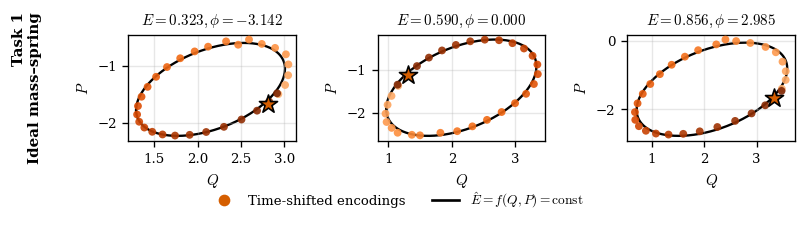

In [27]:
# energy figure (unchanged call)
fig_E, axes_E = plot_task1_conserved_quantities_grid(
    COEFFS['c_const'],
    COEFFS['a'],
    COEFFS['b'],
    COEFFS['c_quad'],
    COEFFS['d'],
    COEFFS['e'],
    closest_indices,
    1000,
    Q_full=Q_full,
    P_full=P_full,
    taus=taus,
    res_train=res_train,
    use_time_encoding=True,
)


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: manuscript_figures/phase_recovery_time_shift_task_1.pdf


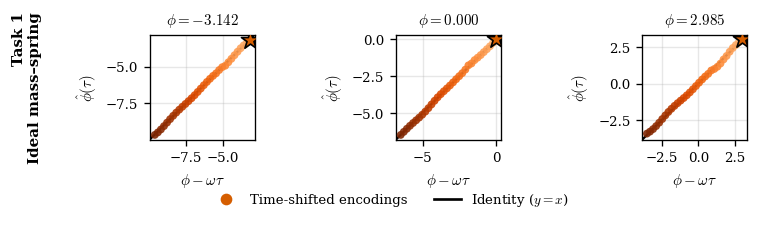

In [28]:
fig_phi, axes_phi = plot_task1_phase_recovery_grid(
    closest_indices,
    phi_hat=phi_hat,        # from time_shift_test's return
    phi0=res_train["phi"],  # true initial phases
    taus=taus,
    omega=1.0,
)

----------------------------------------------------

SEED 52

---------------------------------------


In [5]:
save_dir_path_seed_52 = "./save_directory_mass_spring_seed_52" 


with open("all_dataframes_low_samples_multiple_periods.pkl", "rb") as f:
    df_low_samples_multiple_periods = pickle.load(f)

test_df_low_samples_multiple_periods = df_low_samples_multiple_periods['data_df_low_samples_multiple_periods']
test_id_df_low_samples_multiple_periods = df_low_samples_multiple_periods['id_df_low_samples_multiple_periods']

with open("df_high_energy_low_samples.pkl", "rb") as f:
    df_high_energy_low_samples = pickle.load(f)


test_df_high_energy_low_samples = df_high_energy_low_samples['test_df_high_energy_low_samples']
test_id_df_high_energy_low_samples = df_high_energy_low_samples['test_id_df_high_energy_low_samples']


with open("all_dataframes_low_samples.pkl", "rb") as f:
    loaded_dfs_low_samples = pickle.load(f)

# Access them like before:
train_df_low_samples = loaded_dfs_low_samples['train_df_low_samples']
train_id_df_low_samples = loaded_dfs_low_samples['train_id_df_low_samples']


In [6]:
Tmax = 6.4926248
device = "cuda"
mapping_net_seed_52 = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)



checkpoint_path_seed_52 = os.path.join(save_dir_path_seed_52, "best_model.pt")

load_checkpoint(path=checkpoint_path_seed_52, mapping_net=mapping_net_seed_52, device=device, optimizer=None, scheduler=None)

inverse_net_seed_52 = InverseStackedHamiltonianNetwork(forward_network=mapping_net_seed_52)

overall_seeds_save_path = "seed_results"


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [14]:
variance_results_multiple_periods_seed_52 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net_seed_52,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_52 = os.path.join(overall_seeds_save_path, "variance_results_seed_52")
os.makedirs(save_dir_constancy_seed_52, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_52, "task_1_variance_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(variance_results_multiple_periods_seed_52, f)

Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.034973
IQR: [0.026573, 0.088265]
95% BCa bootstrap CI for median (over trajectories): [0.028169, 0.068014]
N_traj=24, N_obs=97, N_permutations=20
First valid point count: 3


In [7]:
variance_results_high_energy_seed_52 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net_seed_52,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_52 = os.path.join(overall_seeds_save_path, "variance_results_seed_52")
os.makedirs(save_dir_constancy_seed_52, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_52, "task_1_variance_results_high_energy.pkl"), "wb") as f:
    pickle.dump(variance_results_high_energy_seed_52, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.107980
IQR: [0.065551, 0.339050]
95% BCa bootstrap CI for median (over trajectories): [0.076113, 0.312726]
N_traj=25, N_obs=32, N_permutations=20
First valid point count: 2


In [7]:


SETS = {"Train": (train_df_low_samples, train_id_df_low_samples),
"TestA": (test_df_low_samples_multiple_periods, test_id_df_low_samples_multiple_periods),
"TestB": (test_df_high_energy_low_samples, test_id_df_high_energy_low_samples)}



res_ms_seed_52 = run_constancy_experiment_1d(
    mapping_net_seed_52, inverse_net_seed_52, Tmax=Tmax, sets=SETS, sigma2=0.1,
)


save_dir_FINAL_CONSTANCY_seed_52 = os.path.join(overall_seeds_save_path, "constancy_results_seed_52")
os.makedirs(save_dir_FINAL_CONSTANCY_seed_52, exist_ok=True)


with open(os.path.join(save_dir_FINAL_CONSTANCY_seed_52, "task_1_constancy_results.pkl"), "xb") as f:
    pickle.dump(res_ms_seed_52, f, protocol=pickle.HIGHEST_PROTOCOL)












model 8d39df97af8fb0ec | outputs 875ce21b13769b21
Train  n_traj=24  n_seg=24  D0 0.0274 [0.0218, 0.0312] | W0max 0.0464 [0.0371, 0.0654] | rms_delta 0.0365 [0.0324, 0.0465] | max_delta 0.0922 [0.0753, 0.155] | rms_disp 1.51 [1.22, 1.72] | noise ratio 0.0816 | D0/Train 1 | floor max 5.97e-07
TestA  n_traj=24  n_seg=96  D0 0.0262 [0.0218, 0.0318] | W0max 0.0654 [0.0497, 0.0733] | rms_delta 0.0369 [0.031, 0.044] | max_delta 0.15 [0.0954, 0.168] | rms_disp 1.51 [1.23, 1.73] | noise ratio 0.0825 | D0/Train 0.954 | floor max 7.17e-07
TestB  n_traj=25  n_seg=25  D0 0.0413 [0.0341, 0.0673] | W0max 0.0992 [0.0699, 0.18] | rms_delta 0.0999 [0.0783, 0.176] | max_delta 0.335 [0.255, 0.66] | rms_disp 2.41 [2.28, 2.59] | noise ratio 0.223 | D0/Train 1.51 | floor max 1.09e-06


In [15]:

TRAIN = (0.2, 1.0)

res_train_seed_52  = encode_grid(mapping_net_seed_52, device, *TRAIN)

report_recovery(res_train_seed_52, name="HJN", scale=False)
report_equations(res_train_seed_52, name="HJN")

DEG_seed_52 = 2
readouts_seed_52 = fit_readouts(res_train_seed_52, degrees=(1, 2, 3, 4))
E_hat_seed_52, phi_hat_seed_52, Q_full_seed_52, P_full_seed_52, taus_seed_52 = time_shift_test(res_train_seed_52, mapping_net_seed_52, device, T_max=Tmax, n_tau=32,
                energy_degree=DEG_seed_52, phase_degree=1, omega=1.0, readouts=readouts_seed_52)






save_dir_conserved_seed_52 = os.path.join(overall_seeds_save_path, "conserved_quantities_results_seed_52")
os.makedirs(save_dir_conserved_seed_52, exist_ok=True)


readout_results_seed_52 = {
    "res_train": res_train_seed_52, "readouts": readouts_seed_52,
    "E_hat": E_hat_seed_52, "phi_hat": phi_hat_seed_52, "Q_full": Q_full_seed_52, "P_full": P_full_seed_52, "taus": taus_seed_52,
    "energy_degree": DEG_seed_52, "Tmax": Tmax
}

with open(os.path.join(save_dir_conserved_seed_52, "mass_spring_results.pkl"), "wb") as f:
    pickle.dump(readout_results_seed_52, f)
print("saved")



[HJN]  ENERGY RECOVERY     train E in (0.2, 1.0)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |   -0.0010 || 0.2055 [0.1031, 0.3083] p95=0.3895 (30.8%)
  2 |    0.9962 || 0.0104 [0.0058, 0.0149] p95=0.0286 (1.9%)
  3 |    0.9994 || 0.0036 [0.0016, 0.0062] p95=0.0114 (0.7%)
  4 |    0.9995 || 0.0031 [0.0013, 0.0055] p95=0.0104 (0.6%)

[HJN]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9997 |  0.9995 || 0.7788 [0.4775, 1.1802] p95=2.2680
  2 |  0.9999 |  1.0000 || 0.3013 [0.1375, 0.5275] p95=0.9259
  3 |  0.9999 |  0.9999 || 0.3605 [0.1623, 0.5979] p95=0.8379
  4 |  1.0000 |  1.0000 || 0.1581 [0.0752, 0.2602] p95=0.4318

------------------------------------------------------------------------------
[HJN]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
------------------------------------------------------------------------------
ENERGY (degree-2):
  E = +0.9475 

In [16]:
save_dir_prediction_seed_52 = os.path.join(overall_seeds_save_path, "prediction_results_all_trajectories_seed_52")
os.makedirs(save_dir_prediction_seed_52, exist_ok=True)


all_trajectories_results_multiple_periods_seed_52 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_52, "task_1_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods_seed_52, f)

print("Rollout extrapolation done")


all_trajectories_results_high_energy_seed_52 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_52, "task_1_results_high_energy.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_high_energy_seed_52, f)

print("Energy extrapolation done")

Rollout extrapolation done
Energy extrapolation done


In [17]:
save_dir_prediction_single_seed_52 = os.path.join(overall_seeds_save_path, "prediction_results_single_trajectory_seed_52")
os.makedirs(save_dir_prediction_single_seed_52, exist_ok=True)


single_trajectory_multiple_periods_results_seed_52 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    3,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    case="harmonic_oscillator",
    length=3.0, k=1, mass=1, g=9.81, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_52, "task_1_single_traj_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results_seed_52, f)


print("Rollout extrapolation done")

single_trajectory_high_energy_results_seed_52 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    6,
    mapping_net_seed_52,
    inverse_net_seed_52,
    device,
    Tmax,
    case="harmonic_oscillator",
    length=3.0, k=1, mass=1, g=9.81, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_52, "task_1_single_traj_results_high_energy.pkl"), "wb") as f:
    pickle.dump(single_trajectory_high_energy_results_seed_52, f)

print("Energy extrapolation done")


Rollout extrapolation done
Energy extrapolation done


----------------------------------

SEED 62

------------------------------------------------------

In [5]:
save_dir_path_seed_62 = "./save_directory_mass_spring_seed_62" 


with open("all_dataframes_low_samples_multiple_periods.pkl", "rb") as f:
    df_low_samples_multiple_periods = pickle.load(f)

test_df_low_samples_multiple_periods = df_low_samples_multiple_periods['data_df_low_samples_multiple_periods']
test_id_df_low_samples_multiple_periods = df_low_samples_multiple_periods['id_df_low_samples_multiple_periods']

with open("df_high_energy_low_samples.pkl", "rb") as f:
    df_high_energy_low_samples = pickle.load(f)


test_df_high_energy_low_samples = df_high_energy_low_samples['test_df_high_energy_low_samples']
test_id_df_high_energy_low_samples = df_high_energy_low_samples['test_id_df_high_energy_low_samples']


with open("all_dataframes_low_samples.pkl", "rb") as f:
    loaded_dfs_low_samples = pickle.load(f)

# Access them like before:
train_df_low_samples = loaded_dfs_low_samples['train_df_low_samples']
train_id_df_low_samples = loaded_dfs_low_samples['train_id_df_low_samples']


In [6]:
Tmax = 6.4926248
device = "cuda"
mapping_net_seed_62 = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)



checkpoint_path_seed_62 = os.path.join(save_dir_path_seed_62, "best_model.pt")

load_checkpoint(path=checkpoint_path_seed_62, mapping_net=mapping_net_seed_62, device=device, optimizer=None, scheduler=None)

inverse_net_seed_62 = InverseStackedHamiltonianNetwork(forward_network=mapping_net_seed_62)

overall_seeds_save_path = "seed_results"


Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [8]:
variance_results_multiple_periods_seed_62 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net_seed_62,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_62 = os.path.join(overall_seeds_save_path, "variance_results_seed_62")
os.makedirs(save_dir_constancy_seed_62, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_62, "task_1_variance_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(variance_results_multiple_periods_seed_62, f)

Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.043352
IQR: [0.023537, 0.082925]
95% BCa bootstrap CI for median (over trajectories): [0.029554, 0.080044]
N_traj=24, N_obs=97, N_permutations=20
First valid point count: 3


In [7]:
variance_results_high_energy_seed_62 = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net_seed_62,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_seed_62 = os.path.join(overall_seeds_save_path, "variance_results_seed_62")
os.makedirs(save_dir_constancy_seed_62, exist_ok=True)

with open(os.path.join(save_dir_constancy_seed_62, "task_1_variance_results_high_energy.pkl"), "wb") as f:
    pickle.dump(variance_results_high_energy_seed_62, f)


Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.099266
IQR: [0.052579, 0.155296]
95% BCa bootstrap CI for median (over trajectories): [0.053266, 0.137307]
N_traj=25, N_obs=32, N_permutations=20
First valid point count: 2


In [7]:


SETS = {"Train": (train_df_low_samples, train_id_df_low_samples),
"TestA": (test_df_low_samples_multiple_periods, test_id_df_low_samples_multiple_periods),
"TestB": (test_df_high_energy_low_samples, test_id_df_high_energy_low_samples)}



res_ms_seed_62 = run_constancy_experiment_1d(
    mapping_net_seed_62, inverse_net_seed_62, Tmax=Tmax, sets=SETS, sigma2=0.1,
)


save_dir_FINAL_CONSTANCY_seed_62 = os.path.join(overall_seeds_save_path, "constancy_results_seed_62")
os.makedirs(save_dir_FINAL_CONSTANCY_seed_62, exist_ok=True)


with open(os.path.join(save_dir_FINAL_CONSTANCY_seed_62, "task_1_constancy_results.pkl"), "xb") as f:
    pickle.dump(res_ms_seed_62, f, protocol=pickle.HIGHEST_PROTOCOL)












model 01205c7bd4c543b5 | outputs 3291f8c972ff93a8
Train  n_traj=24  n_seg=24  D0 0.0266 [0.0232, 0.0363] | W0max 0.0493 [0.0435, 0.0647] | rms_delta 0.0417 [0.0387, 0.0439] | max_delta 0.11 [0.0968, 0.117] | rms_disp 1.51 [1.22, 1.72] | noise ratio 0.0933 | D0/Train 1 | floor max 5.50e-07
TestA  n_traj=24  n_seg=96  D0 0.0304 [0.0248, 0.0356] | W0max 0.0561 [0.0492, 0.0917] | rms_delta 0.0426 [0.0398, 0.045] | max_delta 0.121 [0.112, 0.185] | rms_disp 1.51 [1.23, 1.73] | noise ratio 0.0953 | D0/Train 1.14 | floor max 5.55e-07
TestB  n_traj=25  n_seg=25  D0 0.0485 [0.032, 0.07] | W0max 0.114 [0.0719, 0.156] | rms_delta 0.116 [0.0724, 0.17] | max_delta 0.423 [0.223, 0.589] | rms_disp 2.41 [2.28, 2.59] | noise ratio 0.26 | D0/Train 1.82 | floor max 7.54e-07


In [9]:

TRAIN = (0.2, 1.0)

res_train_seed_62  = encode_grid(mapping_net_seed_62, device, *TRAIN)

report_recovery(res_train_seed_62, name="HJN", scale=False)
report_equations(res_train_seed_62, name="HJN")

DEG_seed_62 = 2
readouts_seed_62 = fit_readouts(res_train_seed_62, degrees=(1, 2, 3, 4))
E_hat_seed_62, phi_hat_seed_62, Q_full_seed_62, P_full_seed_62, taus_seed_62 = time_shift_test(res_train_seed_62, mapping_net_seed_62, device, T_max=Tmax, n_tau=32,
                energy_degree=DEG_seed_62, phase_degree=1, omega=1.0, readouts=readouts_seed_62)






save_dir_conserved_seed_62 = os.path.join(overall_seeds_save_path, "conserved_quantities_results_seed_62")
os.makedirs(save_dir_conserved_seed_62, exist_ok=True)


readout_results_seed_62 = {
    "res_train": res_train_seed_62, "readouts": readouts_seed_62,
    "E_hat": E_hat_seed_62, "phi_hat": phi_hat_seed_62, "Q_full": Q_full_seed_62, "P_full": P_full_seed_62, "taus": taus_seed_62,
    "energy_degree": DEG_seed_62, "Tmax": Tmax
}

with open(os.path.join(save_dir_conserved_seed_62, "mass_spring_results.pkl"), "wb") as f:
    pickle.dump(readout_results_seed_62, f)
print("saved")



[HJN]  ENERGY RECOVERY     train E in (0.2, 1.0)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |   -0.0010 || 0.2052 [0.1014, 0.3074] p95=0.3891 (31.0%)
  2 |    0.9836 || 0.0207 [0.0107, 0.0351] p95=0.0588 (4.3%)
  3 |    0.9994 || 0.0043 [0.0019, 0.0069] p95=0.0109 (0.7%)
  4 |    0.9999 || 0.0016 [0.0008, 0.0028] p95=0.0056 (0.3%)

[HJN]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9990 |  0.9994 || 1.1875 [0.5679, 1.8704] p95=2.9623
  2 |  0.9999 |  0.9999 || 0.3990 [0.1781, 0.6938] p95=1.2527
  3 |  0.9998 |  0.9998 || 0.7842 [0.4152, 1.1068] p95=1.4216
  4 |  1.0000 |  1.0000 || 0.1491 [0.0681, 0.2507] p95=0.4883

------------------------------------------------------------------------------
[HJN]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
------------------------------------------------------------------------------
ENERGY (degree-2):
  E = +1.8899 

In [10]:
save_dir_prediction_seed_62 = os.path.join(overall_seeds_save_path, "prediction_results_all_trajectories_seed_62")
os.makedirs(save_dir_prediction_seed_62, exist_ok=True)


all_trajectories_results_multiple_periods_seed_62 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_62, "task_1_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods_seed_62, f)

print("Rollout extrapolation done")


all_trajectories_results_high_energy_seed_62 = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_seed_62, "task_1_results_high_energy.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_high_energy_seed_62, f)

print("Energy extrapolation done")

Rollout extrapolation done
Energy extrapolation done


In [11]:
save_dir_prediction_single_seed_62 = os.path.join(overall_seeds_save_path, "prediction_results_single_trajectory_seed_62")
os.makedirs(save_dir_prediction_single_seed_62, exist_ok=True)


single_trajectory_multiple_periods_results_seed_62 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    3,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    case="harmonic_oscillator",
    length=3.0, k=1, mass=1, g=9.81, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_62, "task_1_single_traj_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(single_trajectory_multiple_periods_results_seed_62, f)


print("Rollout extrapolation done")

single_trajectory_high_energy_results_seed_62 = test_model_varying_observation_single_trajectory(
    get_data_from_trajectory_id,
    "mse",
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    6,
    mapping_net_seed_62,
    inverse_net_seed_62,
    device,
    Tmax,
    case="harmonic_oscillator",
    length=3.0, k=1, mass=1, g=9.81, constant=2.4,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_single_seed_62, "task_1_single_traj_results_high_energy.pkl"), "wb") as f:
    pickle.dump(single_trajectory_high_energy_results_seed_62, f)

print("Energy extrapolation done")


Rollout extrapolation done
Energy extrapolation done


--------------------------------------------

NO HSIC ABLATION

-----------------------------------------------------

In [5]:
save_dir_path_no_HSIC = "./save_directory_mass_spring_NO_HSIC_3" 


with open("all_dataframes_low_samples_multiple_periods.pkl", "rb") as f:
    df_low_samples_multiple_periods = pickle.load(f)

test_df_low_samples_multiple_periods = df_low_samples_multiple_periods['data_df_low_samples_multiple_periods']
test_id_df_low_samples_multiple_periods = df_low_samples_multiple_periods['id_df_low_samples_multiple_periods']

with open("df_high_energy_low_samples.pkl", "rb") as f:
    df_high_energy_low_samples = pickle.load(f)


test_df_high_energy_low_samples = df_high_energy_low_samples['test_df_high_energy_low_samples']
test_id_df_high_energy_low_samples = df_high_energy_low_samples['test_id_df_high_energy_low_samples']


with open("all_dataframes_low_samples.pkl", "rb") as f:
    loaded_dfs_low_samples = pickle.load(f)

# Access them like before:
train_df_low_samples = loaded_dfs_low_samples['train_df_low_samples']
train_id_df_low_samples = loaded_dfs_low_samples['train_id_df_low_samples']

In [6]:
Tmax = 6.4926248
device = "cuda"
mapping_net_no_HSIC = SimpleStackedHamiltonianNetwork(
        #Hpw many Step_1 + Step_2 layers to stack
    n_layers=10,
        # MLP Architecture parameters
    hidden_dims= [33, 60, 32],
    n_hidden_layers = None,   #Leave None if you provide list on hidden_dims
        
        # Activation parameters
    activation = 'gelu',
    activation_params = None,
    final_activation = None,   #Final layer activation function
    #final_activation_only_on_final_layer = True,
    tanh_wrapper = False,
        
        # Initialization parameters
    weight_init = 'orthogonal',
    weight_init_params = {'gain': 1},
    bias_init = 'zeros',
    bias_init_value = 0.0,
        
        
        # Architectural choices
    use_bias = True,
    use_layer_norm = False,
    
    # Input/Output parameters
    input_dim = 2,  # x or u and t
    output_dim = 1,  # scalar G or F
    a_eps_min= 0.5,  # Minimum value for a
    a_eps_max= 2,  # Maximum value for a  
    a_k= 0.1,

    step_1_a_mean_innit= 1.2,
    step_2_a_mean_innit= 1.2,
    std_to_mean_ratio_a_mean_init= 0.0,

    step_1_gamma_mean_innit= 0.5,
    step_2_gamma_mean_innit= 0.5,
    std_to_mean_ratio_gamma_mean_init= 0.0,

    step_1_c1_mean_innit= 0.0,
    step_2_c1_mean_innit= 0.0,
    std_to_mean_ratio_c1_mean_init= 1.0,

    step_1_c2_mean_innit= 0.0,
    step_2_c2_mean_innit= 0.0,
    std_to_mean_ratio_c2_mean_init= 1.0,

    bound_innit=0.0,
).to(device)



checkpoint_path_no_HSIC = os.path.join(save_dir_path_no_HSIC, "best_model.pt")

load_checkpoint(path=checkpoint_path_no_HSIC, mapping_net=mapping_net_no_HSIC, device=device, optimizer=None, scheduler=None)

inverse_net_no_HSIC = InverseStackedHamiltonianNetwork(forward_network=mapping_net_no_HSIC)

overall_ablation_save_path = "no_HSIC_ablation_results"




Successfully loaded model
Created inverse network with 10 reverse layers


/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/modules.py:4967: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location=devic

In [7]:
variance_results_multiple_periods_no_HSIC = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net_no_HSIC,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=False,)

save_dir_constancy_no_HSIC = os.path.join(overall_ablation_save_path, "variance_results_no_HSIC")
os.makedirs(save_dir_constancy_no_HSIC, exist_ok=True)


with open(os.path.join(save_dir_constancy_no_HSIC, "task_1_variance_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(variance_results_multiple_periods_no_HSIC, f)



In [7]:
variance_results_high_energy_no_HSIC = test_model_variance_with_varying_observed_points(get_data_from_trajectory_id,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net_no_HSIC,
    Tmax,
    device,
    n_permutations=20,
    confidence_level=0.95,
    valid_fraction_threshold=0.5,
    rng_seed=42,
    verbose=True,)

save_dir_constancy_no_HSIC = os.path.join(overall_ablation_save_path, "variance_results_no_HSIC")
os.makedirs(save_dir_constancy_no_HSIC, exist_ok=True)


with open(os.path.join(save_dir_constancy_no_HSIC, "task_1_variance_results_high_energy.pkl"), "wb") as f:
    pickle.dump(variance_results_high_energy_no_HSIC, f)



Permutation 1/20
Permutation 2/20
Permutation 3/20
Permutation 4/20
Permutation 5/20
Permutation 6/20
Permutation 7/20
Permutation 8/20
Permutation 9/20
Permutation 10/20
Permutation 11/20
Permutation 12/20
Permutation 13/20
Permutation 14/20
Permutation 15/20
Permutation 16/20
Permutation 17/20
Permutation 18/20
Permutation 19/20
Permutation 20/20

=== Within-Segment Consistency at Full Observation ===
Median across trajectories: 0.093807
IQR: [0.067476, 0.171480]
95% BCa bootstrap CI for median (over trajectories): [0.069475, 0.148720]
N_traj=25, N_obs=32, N_permutations=20
First valid point count: 2


In [7]:


SETS = {"Train": (train_df_low_samples, train_id_df_low_samples),
"TestA": (test_df_low_samples_multiple_periods, test_id_df_low_samples_multiple_periods),
"TestB": (test_df_high_energy_low_samples, test_id_df_high_energy_low_samples)}



res_ms_no_HSIC = run_constancy_experiment_1d(
    mapping_net_no_HSIC, inverse_net_no_HSIC, Tmax=Tmax, sets=SETS, sigma2=0.1,
)


save_dir_FINAL_CONSTANCY_no_HSIC = os.path.join(overall_ablation_save_path, "constancy_results_no_HSIC")
os.makedirs(save_dir_FINAL_CONSTANCY_no_HSIC, exist_ok=True)


with open(os.path.join(save_dir_FINAL_CONSTANCY_no_HSIC, "task_1_constancy_results.pkl"), "xb") as f:
    pickle.dump(res_ms_no_HSIC, f, protocol=pickle.HIGHEST_PROTOCOL)












model f902f9626d47337b | outputs c0e50d4b82fe55bd
Train  n_traj=24  n_seg=24  D0 0.0215 [0.0189, 0.0267] | W0max 0.0406 [0.0312, 0.0559] | rms_delta 0.0327 [0.0306, 0.0347] | max_delta 0.0848 [0.0743, 0.0926] | rms_disp 1.51 [1.22, 1.72] | noise ratio 0.0731 | D0/Train 1 | floor max 7.95e-07
TestA  n_traj=24  n_seg=96  D0 0.0235 [0.0193, 0.0276] | W0max 0.0512 [0.04, 0.0599] | rms_delta 0.0331 [0.0293, 0.0359] | max_delta 0.0989 [0.0861, 0.123] | rms_disp 1.51 [1.23, 1.73] | noise ratio 0.074 | D0/Train 1.09 | floor max 9.12e-07
TestB  n_traj=25  n_seg=25  D0 0.038 [0.0268, 0.0548] | W0max 0.0735 [0.0542, 0.128] | rms_delta 0.0906 [0.0671, 0.137] | max_delta 0.272 [0.182, 0.459] | rms_disp 2.41 [2.28, 2.59] | noise ratio 0.203 | D0/Train 1.77 | floor max 8.60e-07


In [5]:
"""
Latent <-> physics recovery for HJN.

Complements the constancy experiment. Constancy shows (Q,P) are constant ALONG
an orbit (the latents are SOME invariant). This shows the CROSS-orbit fact: how
(Q,P) depend on the true conserved quantities (E, phi), and that a LOW-ORDER
polynomial reads them back out -- in-distribution.
No loss term ever sees E or phi (only reconstruction MAE + an HSIC penalty that
enforces independence BETWEEN Q and P, not identity WITH the physics), so the
recovery is emergent.

Two structural laws (the recovered DEGREE is a diagnostic of how affine the
learned canonical map is; nothing forces a particular degree a priori):
  * ENERGY: E = 1/2(q^2+p^2) is quadratic in (q,p); reported as the recovered
    degree-2 quadratic form (eigenvalues of its quadratic part give the
    positive-definite / closed-orbit check) AND the degree-3 form for fidelity.
  * PHASE: phi = atan2(q,p) is an ANGLE; reported as the degree-1 affine-angle
    one-liner AND the degree-2 form.

Statistics: errors live on a DETERMINISTIC grid with spatially correlated
residuals, so we do NOT bootstrap (no i.i.d. resampling unit). We report the
descriptive error field: median [p25, p75], p95. A true CI would need multiple
training seeds (hook at the bottom).

Reporting is feature-agnostic, so the same tables run on HJN's (Q,P) and the
baseline's C_k via `report_recovery(...)`.

Assumes `mapping_net` (encoder: mapping_net(q,p,t)->(Q,P,t)) and `device` exist.
torch is imported lazily inside the encoder so the analysis path runs without it.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold


# ======================================================================
# Data + encoding
# ======================================================================
def sho_initial_conditions(E, phi):
    """(E, phi) -> (q, p) for H = 1/2 (q^2+p^2). atan2(q,p)=phi, 1/2(q^2+p^2)=E."""
    E = np.asarray(E, float); phi = np.asarray(phi, float)
    return np.sqrt(2 * E) * np.sin(phi), np.sqrt(2 * E) * np.cos(phi)


def build_grid(E_lo, E_hi, n_E=40, n_phi=40):
    Ea = np.linspace(E_lo, E_hi, n_E)
    pa = np.linspace(-np.pi, np.pi, n_phi, endpoint=False)
    EE, PP = np.meshgrid(Ea, pa, indexing="ij")
    E, phi = EE.ravel(), PP.ravel()
    q, p = sho_initial_conditions(E, phi)
    return E, phi, q, p


def encode_at_reference_time(mapping_net, q, p, device, reference_time=0.0):
    """No torch.no_grad(): the HJL forward uses autograd internally; .detach() outputs."""
    import torch
    q_t = torch.as_tensor(np.asarray(q, np.float32), device=device)
    p_t = torch.as_tensor(np.asarray(p, np.float32), device=device)
    t_t = torch.full_like(q_t, float(reference_time))
    Q, P, _ = mapping_net(q_t, p_t, t_t)
    return Q.detach().cpu().numpy().astype(float), P.detach().cpu().numpy().astype(float)


def encode_grid(mapping_net, device, E_lo, E_hi, n_E=40, n_phi=40, reference_time=0.0):
    E, phi, q, p = build_grid(E_lo, E_hi, n_E, n_phi)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    return dict(E=E, phi=phi, q=q, p=p, feats=np.column_stack([Q, P]), band=(E_lo, E_hi))





# ======================================================================
# Core: out-of-fold prediction, generalization, equations
# ======================================================================
def _r2(y, yhat):
    y = np.asarray(y, float)
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


def _poly(degree, scale=False):
    """Polynomial least-squares read-out. `scale` toggles input standardisation:
    it leaves predictions and R^2 unchanged (an invertible affine reparameterisation
    of the features) and only changes coefficient values, so it is OFF by default
    so that the fitted model IS the equation reported in raw (Q,P) units. Turn it
    ON only if a high-degree solve is ill-conditioned; it never affects results."""
    steps = [StandardScaler()] if scale else []
    steps += [PolynomialFeatures(degree, include_bias=True),
              LinearRegression(fit_intercept=False)]
    return make_pipeline(*steps)


def _oof_scalar(feats, y, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    y = np.asarray(y, float); pred = np.zeros_like(y)
    for tr, te in kf.split(feats):
        pred[te] = _poly(degree, scale).fit(feats[tr], y[tr]).predict(feats[te])
    return pred




def _oof_phase(feats, phi, degree, n_splits=5, seed=0, scale=False):
    kf = KFold(n_splits, shuffle=True, random_state=seed)
    c, s = np.cos(phi), np.sin(phi); ch, sh = np.zeros_like(c), np.zeros_like(s)
    for tr, te in kf.split(feats):
        m = _poly(degree, scale).fit(feats[tr], np.column_stack([c[tr], s[tr]]))
        o = m.predict(feats[te]); ch[te], sh[te] = o[:, 0], o[:, 1]
    return np.arctan2(sh, ch)




def angular_error_deg(phi_true, phi_hat):
    d = np.arctan2(np.sin(phi_hat - phi_true), np.cos(phi_hat - phi_true))
    return np.abs(d) * 180.0 / np.pi


def err_stats(abs_err):
    """Descriptive spread (no distributional assumption, no bootstrap)."""
    a = np.asarray(abs_err, float)
    q25, med, q75, p95 = np.percentile(a, [25, 50, 75, 95])
    return dict(median=med, p25=q25, p75=q75, p95=p95, mean=a.mean())


def _terms(names, coef):
    """Format a polynomial as a coefficient string in raw (Q,P) units."""
    parts = [f"{c:+.4f}" if n == "1" else f"{c:+.4f}·{n}" for n, c in zip(names, coef)]
    return " ".join(parts).replace("Q P", "QP")


def energy_equation(feats, E, degree, scale=False):
    """Fit the energy read-out and expose both its coefficients (raw Q,P units,
    the displayed equation) and the fitted model itself, so the SAME object can be
    reused as the time-shift instrument. For degree 2 we also return the quadratic
    part's eigenvalues (positive-definite => closed-orbit invariant)."""
    model = _poly(degree, scale).fit(feats, E)
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    coef = model.named_steps["linearregression"].coef_
    out = dict(names=names, coef=coef, degree=degree, model=model)
    if degree == 2 and feats.shape[1] == 2 and not scale:
        d = dict(zip(names, coef))
        M = np.array([[d["Q^2"], d["Q P"] / 2], [d["Q P"] / 2, d["P^2"]]])
        eig = np.linalg.eigvalsh(M)
        out.update(eig=eig, posdef=bool(eig.min() > 0))
    return out


def phase_poly_angle(feats, phi, degree, scale=False):
    """Fit the phase read-out and expose both the displayed equation
    (phi_hat = atan2(sin-poly, cos-poly), raw Q,P units; degree 1 = the affine-angle
    one-liner) and the fitted multi-output model, so the SAME object is reused as
    the time-shift instrument."""
    model = _poly(degree, scale).fit(feats, np.column_stack([np.cos(phi), np.sin(phi)]))
    pf = model.named_steps["polynomialfeatures"]
    names = pf.get_feature_names_out(["Q", "P"])
    cos_coef, sin_coef = model.named_steps["linearregression"].coef_  # rows: cos, sin
    o = model.predict(feats)
    phi_hat = np.arctan2(o[:, 1], o[:, 0])
    return dict(num=_terms(names, sin_coef), den=_terms(names, cos_coef),
                err=angular_error_deg(phi, phi_hat), model=model)


# ======================================================================
# Reporters
# ======================================================================
def _fmt(s):
    return f"{s['median']:.4f} [{s['p25']:.4f}, {s['p75']:.4f}] p95={s['p95']:.4f}"


def report_recovery(res_train, name="HJN", degrees=(1, 2, 3, 4), scale=False):
    """Feature-agnostic (HJN (Q,P) or baseline C_k). R^2 ladders + descriptive
    error fields, in-distribution (train CV only). `scale` standardises features
    before the polynomial fit; it is OFF by default and never changes any reported
    number (see _poly)."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "=" * 78
    print(f"\n{bar}\n[{name}]  ENERGY RECOVERY     "
          f"train E in {res_train['band']}\n{bar}")
    print(f"{'deg':>3} | {'train R2':>9} || train |dE| med[IQR] p95 (rel%)")
    for dg in degrees:
        oof = _oof_scalar(ft, Et, dg, scale=scale)
        rt = np.median(np.abs(Et - oof) / np.abs(Et)) * 100
        print(f"{dg:>3} | {_r2(Et, oof):>9.4f} || "
              f"{_fmt(err_stats(np.abs(Et - oof)))} ({rt:.1f}%)")

    print(f"\n{bar}\n[{name}]  PHASE RECOVERY  (angular error in degrees)\n{bar}")
    print(f"{'deg':>3} | {'cos R2':>7} | {'sin R2':>7} || train ang.err med[IQR] p95")
    for dg in degrees:
        ph_tr = _oof_phase(ft, pt, dg, scale=scale)
        print(f"{dg:>3} | {_r2(np.cos(pt), np.cos(ph_tr)):>7.4f} | "
              f"{_r2(np.sin(pt), np.sin(ph_tr)):>7.4f} || "
              f"{_fmt(err_stats(angular_error_deg(pt, ph_tr)))}")


def report_equations(res_train, name="HJN"):
    """HJN structural laws (assumes 2 canonical latents)."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    bar = "-" * 78
    print(f"\n{bar}\n[{name}]  RECOVERED LAWS  (raw Q,P units; coefficients are "
          f"gauge-dependent -- the STRUCTURE is the robust claim)\n{bar}")

    eq2 = energy_equation(ft, Et, 2)
    print("ENERGY (degree-2):")
    print("  E = " + _terms(eq2["names"], np.round(eq2["coef"], 4)))
    print(f"  eigenvalues of quadratic part = {eq2['eig'].round(3)}  "
          f"positive-definite = {'YES' if eq2['posdef'] else 'NO'}  (=> closed-orbit invariant)")
    eq3 = energy_equation(ft, Et, 3)
    print("ENERGY (degree-3):")
    print("  E = " + _terms(eq3["names"], np.round(eq3["coef"], 4)))

    p1 = phase_poly_angle(ft, pt, 1); s1 = err_stats(p1["err"])
    print("PHASE (degree-1 affine-angle):")
    print(f"  phi_hat = atan2( {p1['num']} ,  {p1['den']} )")
    print(f"  angular error: median {s1['median']:.3f} deg "
          f"[{s1['p25']:.3f}, {s1['p75']:.3f}]  p95={s1['p95']:.3f} deg")
    p2 = phase_poly_angle(ft, pt, 2); s2 = err_stats(p2["err"])
    print("PHASE (degree-2):")
    print("  phi_hat = atan2( NUM , DEN ) with")
    print(f"    NUM = {p2['num']}")
    print(f"    DEN = {p2['den']}")
    print(f"  angular error: median {s2['median']:.3f} deg "
          f"[{s2['p25']:.3f}, {s2['p75']:.3f}]  p95={s2['p95']:.3f} deg")


# ======================================================================
# Read-out registry: fit once on the t=0 grid, reuse by degree
# ======================================================================
def fit_readouts(res_train, degrees=(1, 2, 3, 4), scale=False):
    """Fit, once, the energy and phase read-outs for every requested degree on the
    t=0 training grid, caching the actual fitted models. These are the SAME models
    whose coefficients report_equations displays, so the time-shift test applies
    the displayed equations rather than a separate fit. Returns
    {'energy': {d: model}, 'phase': {d: model}, 'degrees': (...)}. Phase models are
    multi-output, predicting [cos phi, sin phi]."""
    ft, Et, pt = res_train["feats"], res_train["E"], res_train["phi"]
    energy = {d: energy_equation(ft, Et, d, scale)["model"] for d in degrees}
    phase  = {d: phase_poly_angle(ft, pt, d, scale)["model"] for d in degrees}
    return dict(energy=energy, phase=phase, degrees=tuple(degrees))


def predict_energy(readouts, feats, degree):
    return readouts["energy"][degree].predict(feats)


def predict_phase(readouts, feats, degree):
    """Recover the angle from the cached degree-`degree` (cos,sin) read-out."""
    o = readouts["phase"][degree].predict(feats)
    return np.arctan2(o[:, 1], o[:, 0])


# ======================================================================
# Time-shift test: does M implement the Hamilton--Jacobi time dependence?
# ======================================================================
def time_shift_test(res_train, mapping_net, device, T_max, n_tau=25,
                    energy_degree=3, phase_degree=2, omega=1.0, readouts=None):
    """Tests whether the encoder learned the TIME dependence of the canonical
    map, not merely a correct snapshot at t=0.

    The grid points (q0,p0) in res_train are states at t=0 of trajectories whose
    conserved quantities are (E, phi). We hold each state FIXED and re-encode it
    at a sweep of times tau in [0, T_max], varying only the time input:
        Q(tau), P(tau) = M(q0, p0, tau).
    A correct H--J map returns the conserved coordinates of the trajectory that
    sits at (q0,p0) at time tau; that trajectory has the SAME energy but an
    initial phase shifted to phi - omega*tau. Hence the predictions:
        (1) recovered energy is flat in tau           (slope dE/dtau ~ 0),
        (2) recovered phase is linear in tau,  slope = -omega.
    The energy read-out f and the (cos,sin) read-out are taken from the cached
    registry `readouts` (built by fit_readouts on the t=0 grid; built here if not
    supplied). Using a degree-`energy_degree`/`phase_degree` read-out, NOT the
    interpretable degrees of the displayed laws: the read-out is a measurement
    instrument here, so we use the most accurate in-distribution fit (energy
    degree 3, phase degree 2 by default) to avoid read-out error masquerading as a
    time-dependence failure. The sweep stays in the training energy range (only the
    phase advances), so the read-out is always evaluated where it was fit. The
    phase read-out is calibrated to the TRUE phase, so the expected slope -omega is
    gauge-independent.

    Note: (state, time) pairs here need not have appeared in training, so the test
    probes the learned CONTINUOUS time dependence, not memorised observations.
    Scope: tau in [0, T_max] (the trained temporal domain) and the integrable
    case, where a global (E, phi) labelling exists."""
    q0, p0 = res_train["q"], res_train["p"]
    E_true, phi0 = res_train["E"], res_train["phi"]
    if readouts is None:
        readouts = fit_readouts(res_train, degrees=(energy_degree, phase_degree))

    taus = np.linspace(0.0, T_max, n_tau)
    E_hat = np.empty((n_tau, q0.size)); phi_hat = np.empty((n_tau, q0.size))
    Q_full = np.empty((n_tau, q0.size)); P_full = np.empty((n_tau, q0.size))
    for i, tau in enumerate(taus):
        Q, P = encode_at_reference_time(mapping_net, q0, p0, device, tau)
        F = np.column_stack([Q, P])
        E_hat[i] = predict_energy(readouts, F, energy_degree)
        phi_hat[i] = predict_phase(readouts, F, phase_degree)
        Q_full[i] = Q
        P_full[i] = P

    A = np.vstack([taus, np.ones_like(taus)]).T            # per-point line fits
    cE, *_ = np.linalg.lstsq(A, E_hat, rcond=None)          # [slope, intercept]
    e_slope = cE[0]
    err = np.abs(E_hat - E_true[None, :]) 
    per_tau_med = np.median(err, axis=1)

    phi_un = np.unwrap(phi_hat, axis=0)                     # unwrap along tau
    cP, *_ = np.linalg.lstsq(A, phi_un, rcond=None)
    p_slope, p_int = cP[0], cP[1]
    resid_deg = np.abs(phi_un - A @ cP).ravel() * 180 / np.pi
    ic_err = np.abs(np.arctan2(np.sin(p_int - phi0), np.cos(p_int - phi0))) * 180 / np.pi

    bar = "=" * 78
    print(f"\n{bar}\nTIME-SHIFT TEST   (fixed state re-encoded at tau in [0, {T_max}], "
          f"{q0.size} points x {n_tau} times)\n"
          f"read-outs fit on the t=0 grid: energy degree {energy_degree}, "
          f"phase degree {phase_degree}\n{bar}")
    print("ENERGY (predicted time-invariant: dE/dtau ~ 0)")
    print(f"  dE/dtau               : {_fmt(err_stats(e_slope))}   (energy / time)")
    print(
    "  Median_j |E_hat(τ,j)-E(j)| over trajectories, "
    f"summarized over τ: {_fmt(err_stats(per_tau_med))}"
)
    print(f"PHASE (predicted linear in tau, slope -omega = {-omega:.3f})")
    print(f"  dphi/dtau             : {_fmt(err_stats(p_slope))}   (rad / time)")
    print(f"  |slope - (-omega)|    : {_fmt(err_stats(np.abs(p_slope + omega)))}")
    print(f"  linear-fit residual   : {_fmt(err_stats(resid_deg))}  deg")
    print(f"  intercept err vs phi0 : {_fmt(err_stats(ic_err))}  deg")

    return E_hat, phi_hat, Q_full, P_full, taus


# ======================================================================
# Qualitative sweeps
# ======================================================================
def plot_energy_sweep(mapping_net, device, E_lo, E_hi, label,
                      phi_fixed=np.pi / 4, n=400, reference_time=0.0):
    E = np.linspace(E_lo, E_hi, n)
    q, p = sho_initial_conditions(E, np.full_like(E, phi_fixed))
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    a1.plot(E, Q, "b"); a1.set_ylabel("Q"); a1.grid(True); a1.set_title(f"Q vs E [{label}]")
    a2.plot(E, P, "r"); a2.set_ylabel("P"); a2.set_xlabel("E"); a2.grid(True); a2.set_title("P vs E")
    plt.tight_layout(); plt.show()


def plot_phase_sweep(mapping_net, device, E_fixed=0.6, n=400, reference_time=0.0):
    phi = np.linspace(-np.pi, np.pi, n)
    q, p = sho_initial_conditions(np.full_like(phi, E_fixed), phi)
    Q, P = encode_at_reference_time(mapping_net, q, p, device, reference_time)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 4))
    a1.plot(phi, Q, "b"); a1.set_xlabel("phi"); a1.set_ylabel("Q"); a1.grid(True)
    a2.plot(phi, P, "r"); a2.set_xlabel("phi"); a2.set_ylabel("P"); a2.grid(True)
    a3.plot(Q, P, "purple"); a3.set_xlabel("Q"); a3.set_ylabel("P"); a3.grid(True)
    a3.set_aspect("equal", adjustable="datalim"); a3.set_title("(Q,P) loop")
    plt.tight_layout(); plt.show()




In [9]:
# ======================================================================
# Runner
# ======================================================================

TRAIN = (0.2, 1.0)

res_train_no_HSIC  = encode_grid(mapping_net_no_HSIC, device, *TRAIN)

report_recovery(res_train_no_HSIC, name="HJN", scale=False)
report_equations(res_train_no_HSIC, name="HJN")

DEG_no_HSIC = 2
readouts_no_HSIC = fit_readouts(res_train_no_HSIC, degrees=(1, 2, 3, 4))
E_hat_no_HSIC, phi_hat_no_HSIC, Q_full_no_HSIC, P_full_no_HSIC, taus_no_HSIC = time_shift_test(res_train_no_HSIC, mapping_net_no_HSIC, device, T_max=Tmax, n_tau=32,
                energy_degree=DEG_no_HSIC, phase_degree=1, omega=1.0, readouts=readouts_no_HSIC)






save_dir_conserved_no_HSIC = os.path.join(overall_ablation_save_path, "conserved_quantities_results_no_HSIC")
os.makedirs(save_dir_conserved_no_HSIC, exist_ok=True)


readout_results_no_HSIC = {
    "res_train": res_train_no_HSIC, "readouts": readouts_no_HSIC,
    "E_hat": E_hat_no_HSIC, "phi_hat": phi_hat_no_HSIC, "Q_full": Q_full_no_HSIC, "P_full": P_full_no_HSIC, "taus": taus_no_HSIC,
    "energy_degree": DEG_no_HSIC, "Tmax": Tmax
}

with open(os.path.join(save_dir_conserved_no_HSIC, "mass_spring_results.pkl"), "wb") as f:
    pickle.dump(readout_results_no_HSIC, f)
print("saved")



[HJN]  ENERGY RECOVERY     train E in (0.2, 1.0)
deg |  train R2 || train |dE| med[IQR] p95 (rel%)
  1 |    0.0038 || 0.2054 [0.1030, 0.3055] p95=0.3891 (30.8%)
  2 |    0.9217 || 0.0444 [0.0213, 0.0759] p95=0.1327 (8.3%)
  3 |    0.9993 || 0.0045 [0.0022, 0.0076] p95=0.0127 (0.8%)
  4 |    0.9999 || 0.0013 [0.0006, 0.0022] p95=0.0042 (0.2%)

[HJN]  PHASE RECOVERY  (angular error in degrees)
deg |  cos R2 |  sin R2 || train ang.err med[IQR] p95
  1 |  0.9910 |  0.9968 || 2.7104 [1.4082, 4.5675] p95=9.7907
  2 |  0.9997 |  0.9997 || 0.7032 [0.3321, 1.2149] p95=1.8041
  3 |  0.9988 |  0.9989 || 1.7526 [0.8768, 2.3477] p95=3.3208
  4 |  0.9999 |  0.9999 || 0.3112 [0.1467, 0.5665] p95=1.0949

------------------------------------------------------------------------------
[HJN]  RECOVERED LAWS  (raw Q,P units; coefficients are gauge-dependent -- the STRUCTURE is the robust claim)
------------------------------------------------------------------------------
ENERGY (degree-2):
  E = +0.4757 

In [10]:
save_dir_prediction_no_HSIC = os.path.join(overall_ablation_save_path, "prediction_results_all_trajectories_no_HSIC")
os.makedirs(save_dir_prediction_no_HSIC, exist_ok=True)


all_trajectories_results_multiple_periods_no_HSIC = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_low_samples_multiple_periods,
    test_df_low_samples_multiple_periods,
    mapping_net_no_HSIC,
    inverse_net_no_HSIC,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_no_HSIC, "task_1_results_multiple_periods.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_multiple_periods_no_HSIC, f)

print("Rollout extrapolation done")


all_trajectories_results_high_energy_no_HSIC = test_model_all_observations_all_trajectories(
    get_data_from_trajectory_id,
    prediction_loss_euclidean,
    test_id_df_high_energy_low_samples,
    test_df_high_energy_low_samples,
    mapping_net_no_HSIC,
    inverse_net_no_HSIC,
    device,
    Tmax,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=False,
)

with open(os.path.join(save_dir_prediction_no_HSIC, "task_1_results_high_energy.pkl"), "wb") as f:
    pickle.dump(all_trajectories_results_high_energy_no_HSIC, f)

print("Energy extrapolation done")

Rollout extrapolation done
Energy extrapolation done
